In [17]:
# FIX 2026-11-04 [Session options]: GPU None -> T4 x2; Internet Off -> On. Required for CUDA and downloading dependencies/data.
import os
import sys
import shutil
import platform
import subprocess
from pathlib import Path

print("Python hiện tại:", sys.version)
print("OS:", platform.platform())
print("GPU:")

nvidia_smi = shutil.which("nvidia-smi")

if nvidia_smi:
    subprocess.run([nvidia_smi], check=False)
else:
    print("Chưa tìm thấy GPU NVIDIA. Hãy bật GPU trong Settings → Accelerator.")

for path in ["/kaggle/working", "/kaggle/temp", "/kaggle/input"]:
    p = Path(path)
    if p.exists():
        print(path, "exists =", True)
        print("Free disk (GB):",
              round(shutil.disk_usage(path).free / 1024**3, 2))

assert Path("/kaggle/working").exists()
assert shutil.which("git"), "Không tìm thấy git"


Python hiện tại: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
OS: Linux-6.18.55+-x86_64-with-glibc2.39
GPU:
Fri Nov  6 17:18:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                         

In [18]:
import os
import sys
import shutil
import subprocess
from pathlib import Path
os.environ["MPLBACKEND"] = "Agg"
print("Notebook Python:", sys.version)
print("Free disk GB:", round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2))
if shutil.which("nvidia-smi"):
    subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"], check=True)


Notebook Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Free disk GB: 14.29
name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


In [1]:
# from pathlib import Path
# log = Path("/kaggle/working/SCLIP_RESULTS/logs/voc20.log")
# lines = log.read_text(errors="replace").splitlines()
# summary = [line for line in lines if "[1449/1449]" in line]
# assert summary, "Benchmark chưa hoàn tất"
# print("SCLIP — ĐÃ CHẠY THÀNH CÔNG")
# print("PASCAL VOC20: 1449 ảnh; benchmark exit code: 0")
# print(summary[-1])
# print("Log:", log)


In [20]:
import socket

for host in ["github.com", "pypi.org"]:
    try:
        print(host, "→", socket.gethostbyname(host))
    except OSError as e:
        print(host, "→ LỖI:", e)

github.com → 140.82.112.4
pypi.org → 151.101.128.223


In [21]:
import os
import shutil
import subprocess
from pathlib import Path

UV = shutil.which("uv")
assert UV, "Không tìm thấy uv"
VENV = Path("/kaggle/working/sclip-venv")
PYTHON = VENV / "bin" / "python"
Path("/kaggle/working/datasets/downloads").mkdir(parents=True, exist_ok=True)
env = os.environ.copy()
env["UV_HTTP_CONNECT_TIMEOUT"] = "120"
env["UV_HTTP_TIMEOUT"] = "300"
subprocess.run([UV, "python", "install", "3.10"], env=env, check=True)
if not PYTHON.exists():
    subprocess.run([UV, "venv", "--python", "3.10", str(VENV)], env=env, check=True)
subprocess.run([str(PYTHON), "--version"], check=True)

Python 3.10.22


Python 3.10 is already installed


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '--version'], returncode=0)

In [24]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
UV = "/usr/local/bin/uv"

# Dùng uv cài pip vào đúng virtual environment
subprocess.run(
    [
        UV, "pip", "install",
        "--python", PYTHON,
        "pip"
    ],
    check=True
)

# Xác minh
subprocess.run(
    [PYTHON, "-m", "pip", "--version"],
    check=True
)

Using Python 3.10.22 environment at: sclip-venv
Checked 1 package in 2ms


pip 26.3 from /kaggle/working/sclip-venv/lib/python3.10/site-packages/pip (python 3.10)


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-m', 'pip', '--version'], returncode=0)

In [25]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"

subprocess.run(
    [
        PYTHON, "-m", "pip", "install",
        "torch==2.0.0",
        "torchvision==0.15.1",
        "--extra-index-url",
        "https://download.pytorch.org/whl/cu118"
    ],
    check=True
)

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu118


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-m', 'pip', 'install', 'torch==2.0.0', 'torchvision==0.15.1', '--extra-index-url', 'https://download.pytorch.org/whl/cu118'], returncode=0)

In [26]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"

code = """
import torch
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))
"""

subprocess.run([PYTHON, "-c", code], check=True)


PyTorch: 2.0.0+cu118
CUDA build: 11.8
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-c', '\nimport torch\nprint("PyTorch:", torch.__version__)\nprint("CUDA build:", torch.version.cuda)\nprint("CUDA available:", torch.cuda.is_available())\nprint("GPU count:", torch.cuda.device_count())\n\nfor i in range(torch.cuda.device_count()):\n    print(f"GPU {i}:", torch.cuda.get_device_name(i))\n'], returncode=0)

In [27]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"

packages = [
    "openmim",
    "mmengine==0.8.4",
    "mmsegmentation==1.1.1",
    "ftfy",
    "regex",
    "yapf==0.40.1",
    "numpy<2",
    "Pillow",
    "opencv-python-headless",
]

subprocess.run(
    [
        PYTHON, "-m", "pip", "install",
        *packages
    ],
    check=True
)

CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-m', 'pip', 'install', 'openmim', 'mmengine==0.8.4', 'mmsegmentation==1.1.1', 'ftfy', 'regex', 'yapf==0.40.1', 'numpy<2', 'Pillow', 'opencv-python-headless'], returncode=0)

In [28]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
MIM = "/kaggle/working/sclip-venv/bin/mim"

subprocess.run(
    [
        PYTHON, "-m", "mim",
        "install", "mmcv==2.0.1"
    ],
    check=True
)

Looking in links: https://download.openmmlab.com/mmcv/dist/cu118/torch2.0.0/index.html


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-m', 'mim', 'install', 'mmcv==2.0.1'], returncode=0)

In [29]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"

code = r'''
import sys
import torch
import torchvision
import mmcv
import mmengine
import mmseg
import numpy

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MMCV:", mmcv.__version__)
print("MMEngine:", mmengine.__version__)
print("MMSegmentation:", mmseg.__version__)
print("NumPy:", numpy.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

from mmcv.ops import get_compiling_cuda_version
print("MMCV compiled CUDA:", get_compiling_cuda_version())

print("DEPENDENCY CHECK PASSED")
'''

subprocess.run(
    [PYTHON, "-c", code],
    check=True
)

Python: 3.10.22 (main, Oct  9 2026, 15:21:30) [Clang 22.1.3 ]
PyTorch: 2.0.0+cu118
Torchvision: 0.15.1+cu118
MMCV: 2.0.1
MMEngine: 0.8.4
MMSegmentation: 1.1.1
NumPy: 1.26.4
CUDA: True
GPU count: 2
MMCV compiled CUDA: 11.8
DEPENDENCY CHECK PASSED


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-c', '\nimport sys\nimport torch\nimport torchvision\nimport mmcv\nimport mmengine\nimport mmseg\nimport numpy\n\nprint("Python:", sys.version)\nprint("PyTorch:", torch.__version__)\nprint("Torchvision:", torchvision.__version__)\nprint("MMCV:", mmcv.__version__)\nprint("MMEngine:", mmengine.__version__)\nprint("MMSegmentation:", mmseg.__version__)\nprint("NumPy:", numpy.__version__)\nprint("CUDA:", torch.cuda.is_available())\nprint("GPU count:", torch.cuda.device_count())\n\nfrom mmcv.ops import get_compiling_cuda_version\nprint("MMCV compiled CUDA:", get_compiling_cuda_version())\n\nprint("DEPENDENCY CHECK PASSED")\n'], returncode=0)

In [32]:
import subprocess
from pathlib import Path

REPO = Path("/kaggle/working/SCLIP")

if not REPO.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/wangf3014/SCLIP.git",
            str(REPO)
        ],
        check=True
    )

print("Commit đang dùng:")
subprocess.run(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    check=True
)

print("\nCác file config:")
for p in sorted((REPO / "configs").glob("cfg_*.py")):
    print(p.name)

print("\nCác file model:")
for p in [
    REPO / "eval.py",
    REPO / "clip_segmentor.py",
    REPO / "custom_datasets.py",
    REPO / "clip" / "__init__.py",
    REPO / "prompts" / "imagenet_template.py",
]:
    print(p.relative_to(REPO), "exists =", p.exists())


Commit đang dùng:
3608360267b6130c1ef18090d7289f17c771cb90

Các file config:
cfg_ade20k.py
cfg_city_scapes.py
cfg_coco_object.py
cfg_coco_stuff10k.py
cfg_coco_stuff164k.py
cfg_context59.py
cfg_context60.py
cfg_voc20.py
cfg_voc21.py

Các file model:
eval.py exists = True
clip_segmentor.py exists = True
custom_datasets.py exists = True
clip/__init__.py exists = True
prompts/imagenet_template.py exists = True


In [33]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
REPO = "/kaggle/working/SCLIP"

code = r'''
import sys
sys.path.insert(0, "/kaggle/working/SCLIP")

import torch
import clip
import clip_segmentor
import custom_datasets
import pamr

print("CLIP source:", clip.__file__)
print("SCLIP model import: OK")
print("Custom datasets import: OK")
print("PAMR import: OK")
print("CUDA available:", torch.cuda.is_available())
'''

result = subprocess.run(
    [PYTHON, "-c", code],
    cwd=REPO,
    text=True,
    capture_output=True
)

print(result.stdout)
if result.stderr:
    print("STDERR:\n", result.stderr[-5000:])

if result.returncode != 0:
    raise RuntimeError(
        "Code SCLIP chưa import được. "
    )

CLIP source: /kaggle/working/SCLIP/clip/__init__.py
SCLIP model import: OK
Custom datasets import: OK
PAMR import: OK
CUDA available: True



In [34]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
REPO = "/kaggle/working/SCLIP"

code = r'''
import sys
sys.path.insert(0, "/kaggle/working/SCLIP")

from mmengine.config import Config

cfg = Config.fromfile(
    "/kaggle/working/SCLIP/configs/cfg_voc20.py"
)

print("Model config:", cfg.model)
print("Dataset type:", cfg.test_dataloader.dataset.type)
print("Data root:", repr(cfg.test_dataloader.dataset.data_root))
print("Data prefix:", cfg.test_dataloader.dataset.data_prefix)
print("Annotation:", cfg.test_dataloader.dataset.ann_file)
print("Pipeline:", cfg.test_dataloader.dataset.pipeline)
'''

subprocess.run(
    [PYTHON, "-c", code],
    cwd=REPO,
    check=True
)

Model config: {'type': 'CLIPForSegmentation', 'clip_path': 'ViT-B/16', 'name_path': './configs/cls_voc20.txt'}
Dataset type: PascalVOC20Dataset
Data root: ''
Data prefix: {'img_path': 'JPEGImages', 'seg_map_path': 'SegmentationClass'}
Annotation: ImageSets/Segmentation/val.txt
Pipeline: [{'type': 'LoadImageFromFile'}, {'type': 'Resize', 'scale': (2048, 336), 'keep_ratio': True}, {'type': 'LoadAnnotations'}, {'type': 'PackSegInputs'}]


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-c', '\nimport sys\nsys.path.insert(0, "/kaggle/working/SCLIP")\n\nfrom mmengine.config import Config\n\ncfg = Config.fromfile(\n    "/kaggle/working/SCLIP/configs/cfg_voc20.py"\n)\n\nprint("Model config:", cfg.model)\nprint("Dataset type:", cfg.test_dataloader.dataset.type)\nprint("Data root:", repr(cfg.test_dataloader.dataset.data_root))\nprint("Data prefix:", cfg.test_dataloader.dataset.data_prefix)\nprint("Annotation:", cfg.test_dataloader.dataset.ann_file)\nprint("Pipeline:", cfg.test_dataloader.dataset.pipeline)\n'], returncode=0)

In [35]:
from pathlib import Path
import urllib.request
import hashlib
import shutil

DATA_DIR = Path("/kaggle/working/datasets")
DATA_DIR.mkdir(parents=True, exist_ok=True)

URL = (
    "https://github.com/ultralytics/assets/releases/download/"
    "v0.0.0/VOCtrainval_11-May-2012.zip"
)

ZIP_FILE = DATA_DIR / "VOC2012.zip"

if not ZIP_FILE.exists():
    urllib.request.urlretrieve(URL, ZIP_FILE)

print("Đã tải:", ZIP_FILE)

Đã tải: /kaggle/working/datasets/VOC2012.zip


In [36]:
import subprocess
import hashlib
from pathlib import Path

VOC_TAR = Path("/kaggle/working/datasets/downloads/VOCtrainval_11-May-2012.tar")
VOC_TAR.parent.mkdir(parents=True, exist_ok=True)
URL = "https://pjreddie.com/media/files/VOCtrainval_11-May-2012.tar"
subprocess.run(["curl", "-fL", "--retry", "2", "--connect-timeout", "30", "--max-time", "1200", URL, "-o", str(VOC_TAR)], check=True)
h = hashlib.md5()
with VOC_TAR.open("rb") as f:
    for chunk in iter(lambda: f.read(8*1024*1024), b""):
        h.update(chunk)
assert h.hexdigest() == "6cd6e144f989b92b3379bac3b3de84fd", "VOC checksum mismatch"
print("VOC download and MD5 check PASSED", round(VOC_TAR.stat().st_size/1024**3, 3), "GB")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   167    0   167    0     0   1158      0 --:--:-- --:--:-- --:--:--  1167
100 1907M  100 1907M    0     0  60.2M      0  0:00:31  0:00:31 --:--:--  104M


VOC download and MD5 check PASSED 1.862 GB


In [37]:
from pathlib import Path
import tarfile

VOC_TAR = Path(
    "/kaggle/working/datasets/downloads/"
    "VOCtrainval_11-May-2012.tar"
)

assert VOC_TAR.exists(), "Không tìm thấy file VOC."
assert VOC_TAR.stat().st_size > 100_000_000, "File quá nhỏ hoặc tải lỗi."

with tarfile.open(VOC_TAR, "r:") as tar:
    members = tar.getnames()

print("Archive entries:", len(members))
print("First entries:")
for name in members[:10]:
    print(" ", name)

required_fragments = [
    "VOC2012/JPEGImages/",
    "VOC2012/SegmentationClass/",
    "VOC2012/ImageSets/Segmentation/val.txt",
]

for fragment in required_fragments:
    found = any(fragment in name for name in members)
    print(fragment, "FOUND =", found)
    assert found, f"Archive thiếu thành phần: {fragment}"

print("Archive validation PASSED")

Archive entries: 40189
First entries:
  VOCdevkit
  VOCdevkit/VOC2012
  VOCdevkit/VOC2012/Annotations
  VOCdevkit/VOC2012/Annotations/2007_000027.xml
  VOCdevkit/VOC2012/Annotations/2007_000032.xml
  VOCdevkit/VOC2012/Annotations/2007_000033.xml
  VOCdevkit/VOC2012/Annotations/2007_000039.xml
  VOCdevkit/VOC2012/Annotations/2007_000042.xml
  VOCdevkit/VOC2012/Annotations/2007_000061.xml
  VOCdevkit/VOC2012/Annotations/2007_000063.xml
VOC2012/JPEGImages/ FOUND = True
VOC2012/SegmentationClass/ FOUND = True
VOC2012/ImageSets/Segmentation/val.txt FOUND = True
Archive validation PASSED


In [38]:
from pathlib import Path
import subprocess
import shutil

DATA_DIR = Path("/kaggle/working/datasets")
VOC_TAR = DATA_DIR / "downloads" / "VOCtrainval_11-May-2012.tar"
VOC_ROOT = DATA_DIR / "VOCdevkit" / "VOC2012"

free_gb = shutil.disk_usage("/kaggle/working").free / 1024**3
print(f"Disk free before extraction: {free_gb:.2f} GB")

if not VOC_ROOT.exists():
    subprocess.run(
        ["tar", "-xf", str(VOC_TAR), "-C", str(DATA_DIR)],
        check=True
    )
else:
    print("VOC2012 đã được giải nén; bỏ qua.")

assert (VOC_ROOT / "JPEGImages").is_dir()
assert (VOC_ROOT / "SegmentationClass").is_dir()
assert (
    VOC_ROOT / "ImageSets" / "Segmentation" / "val.txt"
).is_file()

print("VOC root:", VOC_ROOT)
print("Disk free after extraction:",
      round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2),
      "GB")

Disk free before extraction: 10.61 GB
VOC root: /kaggle/working/datasets/VOCdevkit/VOC2012
Disk free after extraction: 8.68 GB


In [39]:
from pathlib import Path

VOC_ROOT = Path("/kaggle/working/datasets/VOCdevkit/VOC2012")
val_file = VOC_ROOT / "ImageSets" / "Segmentation" / "val.txt"

ids = [
    x.strip()
    for x in val_file.read_text().splitlines()
    if x.strip()
]

missing_images = [
    x for x in ids
    if not (VOC_ROOT / "JPEGImages" / f"{x}.jpg").is_file()
]

missing_masks = [
    x for x in ids
    if not (VOC_ROOT / "SegmentationClass" / f"{x}.png").is_file()
]

print("Validation IDs:", len(ids))
print("Missing images:", len(missing_images))
print("Missing masks:", len(missing_masks))

if missing_images:
    print("Image examples:", missing_images[:10])
if missing_masks:
    print("Mask examples:", missing_masks[:10])

assert len(ids) > 0
assert not missing_images
assert not missing_masks

print("VOC validation integrity check PASSED")

Validation IDs: 1449
Missing images: 0
Missing masks: 0
VOC validation integrity check PASSED


In [40]:
from pathlib import Path
import subprocess

REPO = Path("/kaggle/working/SCLIP")
PYTHON = "/kaggle/working/sclip-venv/bin/python"

VOC_ROOT = "/kaggle/working/datasets/VOCdevkit/VOC2012"
CONFIG_SRC = REPO / "configs" / "cfg_voc20.py"
CONFIG_DIR = REPO / "runtime_configs"
CONFIG_OUT = CONFIG_DIR / "cfg_voc20.py"

CONFIG_DIR.mkdir(parents=True, exist_ok=True)

patch_script = r'''
import sys
from mmengine.config import Config

src, dst, data_root, work_dir = sys.argv[1:5]
cfg = Config.fromfile(src)

cfg.test_dataloader.dataset.data_root = data_root
cfg.work_dir = work_dir
cfg.dump(dst)

print("Runtime config:", dst)
print("Dataset root:", cfg.test_dataloader.dataset.data_root)
print("Model:", cfg.model)
print("Work dir:", cfg.work_dir)
'''

subprocess.run(
    [
        PYTHON, "-c", patch_script,
        str(CONFIG_SRC),
        str(CONFIG_OUT),
        VOC_ROOT,
        "/kaggle/working/SCLIP_RESULTS/work_dirs/voc20",
    ],
    cwd=str(REPO),
    check=True,
)

Runtime config: /kaggle/working/SCLIP/runtime_configs/cfg_voc20.py
Dataset root: /kaggle/working/datasets/VOCdevkit/VOC2012
Model: {'type': 'CLIPForSegmentation', 'clip_path': 'ViT-B/16', 'name_path': './configs/cls_voc20.txt'}
Work dir: /kaggle/working/SCLIP_RESULTS/work_dirs/voc20


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-c', '\nimport sys\nfrom mmengine.config import Config\n\nsrc, dst, data_root, work_dir = sys.argv[1:5]\ncfg = Config.fromfile(src)\n\ncfg.test_dataloader.dataset.data_root = data_root\ncfg.work_dir = work_dir\ncfg.dump(dst)\n\nprint("Runtime config:", dst)\nprint("Dataset root:", cfg.test_dataloader.dataset.data_root)\nprint("Model:", cfg.model)\nprint("Work dir:", cfg.work_dir)\n', '/kaggle/working/SCLIP/configs/cfg_voc20.py', '/kaggle/working/SCLIP/runtime_configs/cfg_voc20.py', '/kaggle/working/datasets/VOCdevkit/VOC2012', '/kaggle/working/SCLIP_RESULTS/work_dirs/voc20'], returncode=0)

In [41]:
import os
import subprocess
from pathlib import Path

REPO = Path("/kaggle/working/SCLIP")
PYTHON = "/kaggle/working/sclip-venv/bin/python"

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO) + os.pathsep + env.get("PYTHONPATH", "")
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"

script = r'''
import sys
sys.path.insert(0, "/kaggle/working/SCLIP")

import torch
from mmengine.config import Config
from mmseg.registry import MODELS
import clip_segmentor
import custom_datasets

cfg = Config.fromfile(
    "/kaggle/working/SCLIP/runtime_configs/cfg_voc20.py"
)

print("Model config:", cfg.model)
print("CUDA:", torch.cuda.is_available())

model = MODELS.build(cfg.model)
print("Model class:", type(model).__name__)

model = model.cuda(0).eval()
print("Model moved to GPU 0:", next(model.parameters()).device)
print("MODEL INIT PASSED")
'''

result = subprocess.run(
    [PYTHON, "-c", script],
    cwd=str(REPO),
    env=env,
    text=True,
    capture_output=True,
    timeout=600,
)

print(result.stdout)
if result.stderr:
    print("STDERR:\n", result.stderr[-6000:])

if result.returncode != 0:
    raise RuntimeError(
        "Khởi tạo mô hình chưa thành công. "
    )

Model config: {'clip_path': 'ViT-B/16', 'name_path': './configs/cls_voc20.txt', 'type': 'CLIPForSegmentation'}
CUDA: True
Model class: CLIPForSegmentation
Model moved to GPU 0: cuda:0
MODEL INIT PASSED

STDERR:
 
  0%|                                               | 0.00/335M [00:00<?, ?iB/s]
  0%|                                      | 1.00M/335M [00:00<00:33, 10.4MiB/s]
  4%|█▌                                    | 14.1M/335M [00:00<00:03, 84.9MiB/s]
  7%|██▊                                   | 24.6M/335M [00:00<00:03, 96.4MiB/s]
 10%|███▊                                  | 33.8M/335M [00:00<00:03, 85.1MiB/s]
 13%|█████                                 | 44.1M/335M [00:00<00:03, 92.4MiB/s]
 16%|██████                                | 53.3M/335M [00:00<00:03, 94.0MiB/s]
 19%|███████                               | 62.4M/335M [00:00<00:03, 88.8MiB/s]
 21%|████████▏                             | 71.9M/335M [00:00<00:03, 88.4MiB/s]
 25%|█████████▍                            | 82.7M/335M [0

In [42]:
import os
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
REPO = "/kaggle/working/SCLIP"

script = r'''
import sys

sys.path.insert(0, "/kaggle/working/SCLIP")

import torch
from mmengine.config import Config
from mmengine.dataset import pseudo_collate
from mmengine.registry import init_default_scope
from mmseg.registry import DATASETS, MODELS, TRANSFORMS

# 1. Đăng ký các thành phần tiêu chuẩn của MMSegmentation.
import mmseg.datasets
import mmseg.datasets.transforms
import mmseg.models

# Đặt scope để pipeline tìm đúng registry của MMSegmentation.
init_default_scope("mmseg")

# 2. Đăng ký các thành phần riêng của SCLIP.
import custom_datasets
import clip_segmentor
import pamr

# 3. Kiểm tra PackSegInputs trong registry của MMSegmentation.
pack_cls = TRANSFORMS.get("PackSegInputs")
print("PackSegInputs registered:", pack_cls is not None, flush=True)

assert pack_cls is not None, (
    "Không tìm thấy PackSegInputs trong mmseg.registry.TRANSFORMS."
)

# 4. Đọc cấu hình.
config_path = "/kaggle/working/SCLIP/runtime_configs/cfg_voc20.py"
cfg = Config.fromfile(config_path)

# 5. Tạo dataset và lấy một mẫu.
dataset = DATASETS.build(cfg.test_dataloader.dataset)

print("Dataset class:", type(dataset).__name__, flush=True)
print("Dataset size:", len(dataset), flush=True)

assert len(dataset) > 0, (
    "Dataset rỗng. Hãy kiểm tra data_root, data_prefix và ann_file."
)

sample = dataset[0]
print("Sample keys:", list(sample.keys()), flush=True)

batch = pseudo_collate([sample])

# 6. Kiểm tra GPU.
assert torch.cuda.is_available(), (
    "Không tìm thấy CUDA. Hãy bật GPU trong Settings của Kaggle Notebook."
)

print("GPU:", torch.cuda.get_device_name(0), flush=True)

# 7. Tạo model.
model = MODELS.build(cfg.model)
model = model.cuda(0).eval()

# 8. Chạy inference trên một ảnh.
with torch.inference_mode():
    predictions = model.test_step(batch)

print("Prediction count:", len(predictions), flush=True)
assert len(predictions) == 1, (
    f"Mong đợi 1 dự đoán, nhưng nhận được {len(predictions)}."
)

pred = predictions[0]
assert hasattr(pred, "pred_sem_seg"), (
    "Model không trả về pred_sem_seg."
)

seg = pred.pred_sem_seg.data

print("Segmentation shape:", tuple(seg.shape), flush=True)
print("Segmentation dtype:", seg.dtype, flush=True)
print(
    "Predicted class IDs:",
    torch.unique(seg).cpu().tolist(),
    flush=True,
)

assert seg.numel() > 0, "Kết quả phân đoạn rỗng."

print("SINGLE-IMAGE INFERENCE PASSED", flush=True)
'''

# Kiểm tra đường dẫn trước khi chạy subprocess.
if not os.path.isfile(PYTHON):
    raise FileNotFoundError(f"Không tìm thấy Python: {PYTHON}")

if not os.path.isdir(REPO):
    raise FileNotFoundError(f"Không tìm thấy repository: {REPO}")

env = os.environ.copy()
env["PYTHONPATH"] = os.pathsep.join(
    path for path in [REPO, env.get("PYTHONPATH", "")] if path
)
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"
env["PYTHONUNBUFFERED"] = "1"

os.makedirs(env["TORCH_HOME"], exist_ok=True)
os.makedirs(env["XDG_CACHE_HOME"], exist_ok=True)

try:
    result = subprocess.run(
        [PYTHON, "-u", "-c", script],
        cwd=REPO,
        env=env,
        capture_output=True,
        text=True,
        timeout=300,
    )
except subprocess.TimeoutExpired as exc:
    # TimeoutExpired có thể trả về bytes dù text=True.
    def to_text(value):
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value or ""

    print("STDOUT:\n", to_text(exc.stdout))
    print("STDERR:\n", to_text(exc.stderr))

    raise RuntimeError(
        "Smoke test vượt quá 300 giây. "
        "Kiểm tra log phía trên để biết đang dừng ở bước nào."
    ) from exc

print("STDOUT:")
print(result.stdout or "(Không có stdout)")

if result.stderr:
    print("STDERR:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        f"Smoke test thất bại với exit code {result.returncode}. "
    )

STDOUT:
PackSegInputs registered: True
Dataset class: PascalVOC20Dataset
Dataset size: 1449
Sample keys: ['inputs', 'data_samples']
GPU: Tesla T4
Prediction count: 1
Segmentation shape: (1, 366, 500)
Segmentation dtype: torch.int64
Predicted class IDs: [0, 2, 10, 14, 16, 19]
SINGLE-IMAGE INFERENCE PASSED



In [43]:
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"

script = r'''
import mmcv, mmengine, mmseg
import mmseg.datasets
import mmseg.datasets.transforms

from mmengine.registry import TRANSFORMS as ENGINE_TRANSFORMS
from mmseg.registry import TRANSFORMS as MMSEG_TRANSFORMS

from mmseg.datasets.transforms import PackSegInputs

print("MMCV:", mmcv.__version__)
print("MMEngine:", mmengine.__version__)
print("MMSeg:", mmseg.__version__)

print("Class:", PackSegInputs)
print("Class module:", PackSegInputs.__module__)

print("Engine registry:", ENGINE_TRANSFORMS)
print("MMSeg registry:", MMSEG_TRANSFORMS)

print(
    "In engine registry:",
    "PackSegInputs" in ENGINE_TRANSFORMS.module_dict
)
print(
    "In MMSeg registry:",
    "PackSegInputs" in MMSEG_TRANSFORMS.module_dict
)

print(
    "Registry parent:",
    getattr(MMSEG_TRANSFORMS, "parent", None)
)
'''

result = subprocess.run(
    [PYTHON, "-c", script],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr[-4000:])

MMCV: 2.0.1
MMEngine: 0.8.4
MMSeg: 1.1.1
Class: <class 'mmseg.datasets.transforms.formatting.PackSegInputs'>
Class module: mmseg.datasets.transforms.formatting
Engine registry:                              Registry of transform                              
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Names                ┃ Objects                                               ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ CenterCrop           │ <class 'mmcv.transforms.processing.CenterCrop'>       │
│ Compose              │ <class 'mmcv.transforms.wrappers.Compose'>            │
│ ImageToTensor        │ <class 'mmcv.transforms.formatting.ImageToTensor'>    │
│ KeyMapper            │ <class 'mmcv.transforms.wrappers.KeyMapper'>          │
│ LoadAnnotations      │ <class 'mmcv.transforms.loading.LoadAnnotations'>     │
│ LoadImageFromFile    │ <class 'mmcv.transforms.loading.LoadImageFromFile'>   │
│ MultiScaleF

In [44]:
import os
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
REPO = "/kaggle/working/SCLIP"

script = r'''
import sys
sys.path.insert(0, "/kaggle/working/SCLIP")

import torch
from mmengine.config import Config
from mmengine.dataset import pseudo_collate
from mmengine.registry import init_default_scope
from mmseg.registry import DATASETS, MODELS, TRANSFORMS

# Đăng ký các thành phần của MMSegmentation.
import mmseg.datasets
import mmseg.datasets.transforms
import mmseg.models

# Đăng ký các thành phần riêng của SCLIP.
import custom_datasets
import clip_segmentor
import pamr

# Đọc cấu hình và thiết lập scope trước khi build dataset/model.
cfg = Config.fromfile(
    "/kaggle/working/SCLIP/runtime_configs/cfg_voc20.py"
)
init_default_scope("mmseg")

# Chỉ định rõ namespace cho các transform dễ bị tra cứu nhầm.
# Duyệt cả dataset wrapper và các pipeline lồng nhau.
def fix_transform_types(node):
    if isinstance(node, dict):
        transform_type = node.get("type")

        if isinstance(transform_type, str):
            if transform_type in (
                "LoadAnnotations",
                "mmcv.LoadAnnotations",
            ):
                node["type"] = "mmseg.LoadAnnotations"
            elif transform_type == "PackSegInputs":
                node["type"] = "mmseg.PackSegInputs"

        for value in node.values():
            fix_transform_types(value)

    elif isinstance(node, (list, tuple)):
        for value in node:
            fix_transform_types(value)

dataset_cfg = cfg.test_dataloader.dataset
fix_transform_types(dataset_cfg)

# Kiểm tra class thực sự được tìm thấy.
for name in ("LoadAnnotations", "PackSegInputs"):
    cls = TRANSFORMS.get(name)
    assert cls is not None, f"Không tìm thấy transform: {name}"
    print(
        f"{name}: {cls.__module__}.{cls.__name__}",
        flush=True,
    )

# Tạo dataset.
dataset = DATASETS.build(dataset_cfg)
print("Dataset class:", type(dataset).__name__, flush=True)
print("Dataset length:", len(dataset), flush=True)

assert len(dataset) > 0, "Dataset rỗng. Hãy kiểm tra cấu hình dữ liệu."

# In pipeline thực tế để kiểm tra namespace.
if hasattr(dataset, "pipeline"):
    print("Dataset pipeline:", dataset.pipeline, flush=True)

# Đọc và xử lý một ảnh.
sample = dataset[0]
print("Sample keys:", list(sample.keys()), flush=True)

assert "inputs" in sample, "Sample thiếu inputs."
assert "data_samples" in sample, "Sample thiếu data_samples."

batch = pseudo_collate([sample])

# Kiểm tra GPU.
assert torch.cuda.is_available(), (
    "Không tìm thấy GPU. Hãy bật GPU trong Settings của Kaggle."
)
print("GPU:", torch.cuda.get_device_name(0), flush=True)

# Tạo model và chạy inference.
model = MODELS.build(cfg.model)
model = model.cuda(0).eval()

with torch.inference_mode():
    predictions = model.test_step(batch)

print("Prediction count:", len(predictions), flush=True)
assert len(predictions) == 1, "Mong đợi một kết quả dự đoán."

pred = predictions[0]
assert hasattr(pred, "pred_sem_seg"), (
    "Model không trả về pred_sem_seg."
)

seg = pred.pred_sem_seg.data
assert seg.numel() > 0, "Kết quả phân đoạn rỗng."

print("Segmentation shape:", tuple(seg.shape), flush=True)
print("Segmentation dtype:", seg.dtype, flush=True)
print(
    "Predicted class IDs:",
    torch.unique(seg).cpu().tolist(),
    flush=True,
)
print("SINGLE-IMAGE INFERENCE PASSED", flush=True)
'''

if not os.path.isfile(PYTHON):
    raise FileNotFoundError(f"Không tìm thấy Python: {PYTHON}")

if not os.path.isdir(REPO):
    raise FileNotFoundError(f"Không tìm thấy repository: {REPO}")

env = os.environ.copy()
env["PYTHONPATH"] = os.pathsep.join(
    path for path in [REPO, env.get("PYTHONPATH", "")] if path
)
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"
env["PYTHONUNBUFFERED"] = "1"

os.makedirs(env["TORCH_HOME"], exist_ok=True)
os.makedirs(env["XDG_CACHE_HOME"], exist_ok=True)

try:
    result = subprocess.run(
        [PYTHON, "-u", "-c", script],
        cwd=REPO,
        env=env,
        capture_output=True,
        text=True,
        timeout=300,
    )
except subprocess.TimeoutExpired as exc:
    def to_text(value):
        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace")
        return value or ""

    print("STDOUT:\n", to_text(exc.stdout))
    print("STDERR:\n", to_text(exc.stderr))

    raise RuntimeError(
        "Vượt quá 300 giây. Kiểm tra log để biết bước đang chạy."
    ) from exc

print("STDOUT:")
print(result.stdout or "(Không có stdout)")

if result.stderr:
    print("STDERR:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        f"Smoke test thất bại với exit code {result.returncode}. "
        "Gửi toàn bộ traceback phía trên nếu vẫn còn lỗi."
    )

STDOUT:
LoadAnnotations: mmseg.datasets.transforms.loading.LoadAnnotations
PackSegInputs: mmseg.datasets.transforms.formatting.PackSegInputs
Dataset class: PascalVOC20Dataset
Dataset length: 1449
Dataset pipeline: Compose(
    LoadImageFromFile(ignore_empty=False, to_float32=False, color_type='color', imdecode_backend='cv2', backend_args=None)
    Resize(scale=(2048, 336), scale_factor=None, keep_ratio=True, clip_object_border=True), backend=cv2), interpolation=bilinear)
    LoadAnnotations(reduce_zero_label=None, imdecode_backend='pillow', backend_args=None)
    PackSegInputs(meta_keys=('img_path', 'seg_map_path', 'ori_shape', 'img_shape', 'pad_shape', 'scale_factor', 'flip', 'flip_direction', 'reduce_zero_label'))
)
Sample keys: ['inputs', 'data_samples']
GPU: Tesla T4
Prediction count: 1
Segmentation shape: (1, 366, 500)
Segmentation dtype: torch.int64
Predicted class IDs: [0, 2, 10, 14, 16, 19]
SINGLE-IMAGE INFERENCE PASSED



In [45]:
import os
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
REPO = "/kaggle/working/SCLIP"

script = r'''
import sys
sys.path.insert(0, "/kaggle/working/SCLIP")

import torch
import mmseg.datasets
import mmseg.datasets.transforms
import mmseg.models

from mmengine.registry import TRANSFORMS as ENGINE_TRANSFORMS
from mmseg.registry import TRANSFORMS as MMSEG_TRANSFORMS
from mmseg.datasets.transforms import PackSegInputs, LoadAnnotations
from mmengine.config import Config
from mmengine.dataset import pseudo_collate
from mmseg.registry import DATASETS, MODELS

# Xác minh implementation segmentation chính thức.
print("MMSeg LoadAnnotations:", LoadAnnotations.__module__)
print("MMSeg PackSegInputs:", PackSegInputs.__module__)

assert LoadAnnotations.__module__.startswith("mmseg.datasets.transforms")
assert PackSegInputs.__module__.startswith("mmseg.datasets.transforms")

# Chuyển hai tên pipeline sang implementation MMSegmentation.
ENGINE_TRANSFORMS.register_module(
    module=LoadAnnotations,
    name="LoadAnnotations",
    force=True
)
ENGINE_TRANSFORMS.register_module(
    module=PackSegInputs,
    name="PackSegInputs",
    force=True
)

print(
    "Engine LoadAnnotations:",
    ENGINE_TRANSFORMS.get("LoadAnnotations")
)
print(
    "Engine PackSegInputs:",
    ENGINE_TRANSFORMS.get("PackSegInputs")
)

import custom_datasets
import clip_segmentor
import pamr

cfg = Config.fromfile(
    "/kaggle/working/SCLIP/runtime_configs/cfg_voc20.py"
)

dataset = DATASETS.build(cfg.test_dataloader.dataset)
print("Dataset length:", len(dataset))

sample = dataset[0]
print("Sample keys:", sample.keys())
print("Image tensor shape:", tuple(sample["inputs"].shape))

batch = pseudo_collate([sample])

model = MODELS.build(cfg.model).cuda(0).eval()

with torch.inference_mode():
    predictions = model.test_step(batch)

assert len(predictions) == 1
pred = predictions[0]
assert hasattr(pred, "pred_sem_seg")

seg = pred.pred_sem_seg.data
print("Segmentation shape:", tuple(seg.shape))
print("Predicted class IDs:", torch.unique(seg).cpu().tolist())
print("SINGLE-IMAGE INFERENCE PASSED")
'''

env = os.environ.copy()
env["PYTHONPATH"] = REPO + os.pathsep + env.get("PYTHONPATH", "")
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"

result = subprocess.run(
    [PYTHON, "-c", script],
    cwd=REPO,
    env=env,
    capture_output=True,
    text=True,
    timeout=300
)

print(result.stdout)
if result.stderr:
    print("STDERR:\n", result.stderr[-6000:])

if result.returncode != 0:
    raise RuntimeError(
        "Inference chưa thành công. Gửi traceback mới để xử lý tiếp."
    )

MMSeg LoadAnnotations: mmseg.datasets.transforms.loading
MMSeg PackSegInputs: mmseg.datasets.transforms.formatting
Engine LoadAnnotations: <class 'mmseg.datasets.transforms.loading.LoadAnnotations'>
Engine PackSegInputs: <class 'mmseg.datasets.transforms.formatting.PackSegInputs'>
Dataset length: 1449
Sample keys: dict_keys(['inputs', 'data_samples'])
Image tensor shape: (3, 336, 459)
Segmentation shape: (1, 366, 500)
Predicted class IDs: [0, 2, 10, 14, 16, 19]
SINGLE-IMAGE INFERENCE PASSED



In [46]:
import os
import subprocess
import time
from pathlib import Path

REPO = Path("/kaggle/working/SCLIP")
PYTHON = "/kaggle/working/sclip-venv/bin/python"

CONFIG = REPO / "runtime_configs" / "cfg_voc20.py"
WORK_DIR = Path("/kaggle/working/SCLIP_RESULTS/work_dirs/voc20")
LOG_DIR = Path("/kaggle/working/SCLIP_RESULTS/logs")
LOG = LOG_DIR / "voc20.log"

WORK_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO) + os.pathsep + env.get("PYTHONPATH", "")
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"

cmd = [
    PYTHON,
    str(REPO / "eval.py"),
    "--config", str(CONFIG),
    "--work-dir", str(WORK_DIR),
]

print("Command:", " ".join(cmd))
print("Log:", LOG)

started = time.time()

with open(LOG, "w", encoding="utf-8") as f:
    f.write("COMMAND: " + " ".join(cmd) + "\n\n")
    f.flush()

    proc = subprocess.run(
        cmd,
        cwd=str(REPO),
        env=env,
        stdout=f,
        stderr=subprocess.STDOUT,
        check=False,
    )

elapsed = round(time.time() - started, 1)

print("Exit code:", proc.returncode)
print("Elapsed seconds:", elapsed)
print("Log path:", LOG)

# In phần cuối log để xem metric hoặc traceback
lines = LOG.read_text(
    encoding="utf-8", errors="replace"
).splitlines()

print("\n--- Last 80 log lines ---")
print("\n".join(lines[-80:]))

if proc.returncode != 0:
    raise RuntimeError(
        "Benchmark chưa hoàn tất. Xem traceback ở log phía trên."
    )

Command: /kaggle/working/sclip-venv/bin/python /kaggle/working/SCLIP/eval.py --config /kaggle/working/SCLIP/runtime_configs/cfg_voc20.py --work-dir /kaggle/working/SCLIP_RESULTS/work_dirs/voc20
Log: /kaggle/working/SCLIP_RESULTS/logs/voc20.log
Exit code: 0
Elapsed seconds: 128.2
Log path: /kaggle/working/SCLIP_RESULTS/logs/voc20.log

--- Last 80 log lines ---
(VERY_HIGH   ) RuntimeInfoHook                    
 -------------------- 
before_test_epoch:
(NORMAL      ) IterTimerHook                      
 -------------------- 
before_test_iter:
(NORMAL      ) IterTimerHook                      
 -------------------- 
after_test_iter:
(NORMAL      ) IterTimerHook                      
(NORMAL      ) SegVisualizationHook               
(BELOW_NORMAL) LoggerHook                         
 -------------------- 
after_test_epoch:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
(BELOW_NORMAL) LoggerHook                         
 --------------

In [49]:
import os
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
REPO = "/kaggle/working/SCLIP"

script = r'''
import sys
sys.path.insert(0, "/kaggle/working/SCLIP")

import torch
import mmseg.datasets
import mmseg.datasets.transforms
import mmseg.models

from mmengine.registry import TRANSFORMS as ENGINE_TRANSFORMS
from mmseg.registry import TRANSFORMS as MMSEG_TRANSFORMS
from mmseg.datasets.transforms import PackSegInputs, LoadAnnotations
from mmengine.config import Config
from mmengine.dataset import pseudo_collate
from mmseg.registry import DATASETS, MODELS

# Xác minh implementation segmentation chính thức.
print("MMSeg LoadAnnotations:", LoadAnnotations.__module__)
print("MMSeg PackSegInputs:", PackSegInputs.__module__)

assert LoadAnnotations.__module__.startswith("mmseg.datasets.transforms")
assert PackSegInputs.__module__.startswith("mmseg.datasets.transforms")

# Chuyển hai tên pipeline sang implementation MMSegmentation.
ENGINE_TRANSFORMS.register_module(
    module=LoadAnnotations,
    name="LoadAnnotations",
    force=True
)
ENGINE_TRANSFORMS.register_module(
    module=PackSegInputs,
    name="PackSegInputs",
    force=True
)

print(
    "Engine LoadAnnotations:",
    ENGINE_TRANSFORMS.get("LoadAnnotations")
)
print(
    "Engine PackSegInputs:",
    ENGINE_TRANSFORMS.get("PackSegInputs")
)

import custom_datasets
import clip_segmentor
import pamr

cfg = Config.fromfile(
    "/kaggle/working/SCLIP/runtime_configs/cfg_voc20.py"
)

dataset = DATASETS.build(cfg.test_dataloader.dataset)
print("Dataset length:", len(dataset))

sample = dataset[0]
print("Sample keys:", sample.keys())
print("Image tensor shape:", tuple(sample["inputs"].shape))

batch = pseudo_collate([sample])

model = MODELS.build(cfg.model).cuda(0).eval()

with torch.inference_mode():
    predictions = model.test_step(batch)

assert len(predictions) == 1
pred = predictions[0]
assert hasattr(pred, "pred_sem_seg")

seg = pred.pred_sem_seg.data
print("Segmentation shape:", tuple(seg.shape))
print("Predicted class IDs:", torch.unique(seg).cpu().tolist())
print("SINGLE-IMAGE INFERENCE PASSED")
'''

env = os.environ.copy()
env["PYTHONPATH"] = REPO + os.pathsep + env.get("PYTHONPATH", "")
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"

result = subprocess.run(
    [PYTHON, "-c", script],
    cwd=REPO,
    env=env,
    capture_output=True,
    text=True,
    timeout=300
)

print(result.stdout)
if result.stderr:
    print("STDERR:\n", result.stderr[-6000:])

if result.returncode != 0:
    raise RuntimeError(
        "Inference chưa thành công. Gửi traceback mới để xử lý tiếp."
    )

MMSeg LoadAnnotations: mmseg.datasets.transforms.loading
MMSeg PackSegInputs: mmseg.datasets.transforms.formatting
Engine LoadAnnotations: <class 'mmseg.datasets.transforms.loading.LoadAnnotations'>
Engine PackSegInputs: <class 'mmseg.datasets.transforms.formatting.PackSegInputs'>
Dataset length: 1449
Sample keys: dict_keys(['inputs', 'data_samples'])
Image tensor shape: (3, 336, 459)
Segmentation shape: (1, 366, 500)
Predicted class IDs: [0, 2, 10, 11, 14, 16, 19]
SINGLE-IMAGE INFERENCE PASSED



In [50]:
from pathlib import Path

REPO = Path("/kaggle/working/SCLIP")
BOOTSTRAP = REPO / "bootstrap_eval.py"

bootstrap_code = r'''
import os
import sys
import runpy

REPO = "/kaggle/working/SCLIP"
EVAL_SCRIPT = os.path.join(REPO, "eval.py")

sys.path.insert(0, REPO)

# Nạp các module MMSegmentation chính thức.
import mmseg.datasets
import mmseg.datasets.transforms
import mmseg.models

from mmengine.registry import TRANSFORMS as ENGINE_TRANSFORMS
from mmseg.datasets.transforms import LoadAnnotations, PackSegInputs

# SCLIP config sử dụng pipeline MMSegmentation, trong khi
# pipeline hiện tại đang tra registry của MMEngine.
ENGINE_TRANSFORMS.register_module(
    module=LoadAnnotations,
    name="LoadAnnotations",
    force=True,
)
ENGINE_TRANSFORMS.register_module(
    module=PackSegInputs,
    name="PackSegInputs",
    force=True,
)

# Nạp thành phần tùy chỉnh của repo trước khi build config.
import custom_datasets
import clip_segmentor
import pamr

print("Registry compatibility patch loaded.", flush=True)

# Giữ nguyên các tham số CLI truyền cho eval.py.
sys.argv[0] = EVAL_SCRIPT
runpy.run_path(EVAL_SCRIPT, run_name="__main__")
'''

BOOTSTRAP.write_text(bootstrap_code, encoding="utf-8")
print("Bootstrap created:", BOOTSTRAP)
print(BOOTSTRAP.read_text()[:500])

Bootstrap created: /kaggle/working/SCLIP/bootstrap_eval.py

import os
import sys
import runpy

REPO = "/kaggle/working/SCLIP"
EVAL_SCRIPT = os.path.join(REPO, "eval.py")

sys.path.insert(0, REPO)

# Nạp các module MMSegmentation chính thức.
import mmseg.datasets
import mmseg.datasets.transforms
import mmseg.models

from mmengine.registry import TRANSFORMS as ENGINE_TRANSFORMS
from mmseg.datasets.transforms import LoadAnnotations, PackSegInputs

# SCLIP config sử dụng pipeline MMSegmentation, trong khi
# pipeline hiện tại đang tra registry của MMEngine.



In [51]:
import os
import subprocess

PYTHON = "/kaggle/working/sclip-venv/bin/python"
REPO = "/kaggle/working/SCLIP"

env = os.environ.copy()
env["PYTHONPATH"] = REPO + os.pathsep + env.get("PYTHONPATH", "")
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"

result = subprocess.run(
    [PYTHON, "bootstrap_eval.py", "--help"],
    cwd=REPO,
    env=env,
    capture_output=True,
    text=True,
    timeout=120,
)

print(result.stdout[:6000])
if result.stderr:
    print("STDERR:\n", result.stderr[-3000:])

if result.returncode != 0:
    raise RuntimeError("Không xác minh được CLI của eval.py.")

Registry compatibility patch loaded.
usage: eval.py [-h] [--config CONFIG] [--work-dir WORK_DIR] [--show]
               [--show_dir SHOW_DIR] [--launcher {none,pytorch,slurm,mpi}]
               [--local_rank LOCAL_RANK]

SCLIP evaluation with MMSeg

options:
  -h, --help            show this help message and exit
  --config CONFIG
  --work-dir WORK_DIR
  --show                show prediction results
  --show_dir SHOW_DIR   directory to save visualizaion images
  --launcher {none,pytorch,slurm,mpi}
                        job launcher
  --local_rank LOCAL_RANK, --local-rank LOCAL_RANK



In [52]:
import os
import subprocess
import time
from pathlib import Path

REPO = Path("/kaggle/working/SCLIP")
PYTHON = "/kaggle/working/sclip-venv/bin/python"

CONFIG = REPO / "runtime_configs" / "cfg_voc20.py"
RESULT_ROOT = Path("/kaggle/working/SCLIP_RESULTS")
WORK_DIR = RESULT_ROOT / "work_dirs" / "voc20"
LOG_DIR = RESULT_ROOT / "logs"

WORK_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

LOG = LOG_DIR / "voc20.log"

env = os.environ.copy()
env.pop("MPLBACKEND", None)
env["MPLBACKEND"] = "Agg"

# FIX: chuyển Path thành str trước khi nối chuỗi
env["PYTHONPATH"] = (
    str(REPO) + os.pathsep + env.get("PYTHONPATH", "")
)

env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"

assert REPO.is_dir(), f"Không tìm thấy repo: {REPO}"
assert CONFIG.is_file(), f"Không tìm thấy config: {CONFIG}"
assert (REPO / "bootstrap_eval.py").is_file()

cmd = [
    PYTHON,
    "bootstrap_eval.py",
    "--config", str(CONFIG),
    "--work-dir", str(WORK_DIR),
]

print("Command:", " ".join(cmd))
print("Log:", LOG)

start = time.time()

with LOG.open("w", encoding="utf-8") as f:
    f.write("COMMAND: " + " ".join(cmd) + "\n\n")
    f.flush()

    proc = subprocess.Popen(
        cmd,
        cwd=str(REPO),
        env=env,
        stdout=f,
        stderr=subprocess.STDOUT,
    )

    while proc.poll() is None:
        time.sleep(15)
        f.flush()

elapsed = round(time.time() - start, 1)

print("Exit code:", proc.returncode)
print("Elapsed seconds:", elapsed)

lines = LOG.read_text(
    encoding="utf-8",
    errors="replace"
).splitlines()

print("\n--- Last 100 log lines ---")
print("\n".join(lines[-100:]))

if proc.returncode != 0:
    raise RuntimeError(
        f"Benchmark thất bại (exit code {proc.returncode}). "
        f"Hãy gửi traceback cuối trong {LOG}."
    )

Command: /kaggle/working/sclip-venv/bin/python bootstrap_eval.py --config /kaggle/working/SCLIP/runtime_configs/cfg_voc20.py --work-dir /kaggle/working/SCLIP_RESULTS/work_dirs/voc20
Log: /kaggle/working/SCLIP_RESULTS/logs/voc20.log
Exit code: 0
Elapsed seconds: 135.0

--- Last 100 log lines ---
after_val_iter:
(NORMAL      ) IterTimerHook                      
(NORMAL      ) SegVisualizationHook               
(BELOW_NORMAL) LoggerHook                         
 -------------------- 
after_val_epoch:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
(BELOW_NORMAL) LoggerHook                         
(LOW         ) ParamSchedulerHook                 
(VERY_LOW    ) CheckpointHook                     
 -------------------- 
after_val:
(VERY_HIGH   ) RuntimeInfoHook                    
 -------------------- 
after_train:
(VERY_HIGH   ) RuntimeInfoHook                    
(VERY_LOW    ) CheckpointHook                     
 ----------------

In [ ]:
# from pathlib import Path
# import json
# import shutil
# import torch
# import sys
# import subprocess

# repo = Path("/kaggle/working/SCLIP")
# root = Path("/kaggle/working/SCLIP_RESULTS")
# archive = root / "voc20_artifacts"

# archive.mkdir(parents=True, exist_ok=True)

# # Sao lưu log benchmark
# log = root / "logs/voc20.log"
# assert log.exists() and log.stat().st_size > 0, "Không tìm thấy log"

# shutil.copy2(log, archive / "voc20.log")

# # Sao lưu config đã chạy
# config = repo / "runtime_configs/cfg_voc20.py"
# assert config.exists(), f"Không tìm thấy config: {config}"
# shutil.copy2(config, archive / "cfg_voc20.py")

# # Lưu báo cáo metric đã xác nhận từ log
# report = {
#     "dataset": "PASCAL VOC20",
#     "split": "val",
#     "images_processed": 1449,
#     "classes": 20,
#     "mIoU_percent": 81.53,
#     "mAcc_percent": 90.29,
#     "aAcc_percent": 91.02,
#     "benchmark_exit_code": 0,
#     "pytorch": torch.__version__,
#     "python": sys.version,
#     "cuda_available": torch.cuda.is_available(),
#     "git_commit": subprocess.check_output(
#         ["git", "-C", str(repo), "rev-parse", "HEAD"],
#         text=True,
#     ).strip(),
# }

# (archive / "metrics.json").write_text(
#     json.dumps(report, indent=2),
#     encoding="utf-8",
# )

# # Tạo file zip nhỏ để tải xuống hoặc lưu thành Kaggle Dataset
# zip_path = shutil.make_archive(
#     str(root / "voc20_artifacts"),
#     "zip",
#     root_dir=archive,
# )

# print(json.dumps(report, indent=2))
# print("\nArtifact archive:", zip_path)
# print("Archive size (MB):", round(Path(zip_path).stat().st_size / 1e6, 2))

In [55]:
from pathlib import Path
import subprocess

REPO = Path("/kaggle/working/SCLIP")
PYTHON = "/kaggle/working/sclip-venv/bin/python"

CONFIG_SRC = REPO / "configs/cfg_voc21.py"
CONFIG_OUT = REPO / "runtime_configs/cfg_voc21.py"
VOC_ROOT = Path("/kaggle/working/datasets/VOCdevkit/VOC2012")
WORK_DIR = Path("/kaggle/working/SCLIP_RESULTS/work_dirs/voc21")

assert CONFIG_SRC.is_file(), f"Không tìm thấy: {CONFIG_SRC}"
assert (VOC_ROOT / "ImageSets/Segmentation/val.txt").is_file()

CONFIG_OUT.parent.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

script = r'''
import sys
from mmengine.config import Config

src, dst, data_root, work_dir = sys.argv[1:5]

# Đọc cấu hình VOC21 gốc, giữ các thiết lập model và nhãn.
cfg = Config.fromfile(src)
cfg.test_dataloader.dataset.data_root = data_root
cfg.work_dir = work_dir
cfg.dump(dst)

print("Config:", dst)
print("Dataset:", cfg.test_dataloader.dataset)
print("Model:", cfg.model)
'''

subprocess.run(
    [
        PYTHON, "-c", script,
        str(CONFIG_SRC),
        str(CONFIG_OUT),
        str(VOC_ROOT),
        str(WORK_DIR),
    ],
    cwd=str(REPO),
    check=True,
)

Config: /kaggle/working/SCLIP/runtime_configs/cfg_voc21.py
Dataset: {'type': 'PascalVOCDataset', 'data_root': '/kaggle/working/datasets/VOCdevkit/VOC2012', 'data_prefix': {'img_path': 'JPEGImages', 'seg_map_path': 'SegmentationClass'}, 'ann_file': 'ImageSets/Segmentation/val.txt', 'pipeline': [{'type': 'LoadImageFromFile'}, {'type': 'Resize', 'scale': (2048, 336), 'keep_ratio': True}, {'type': 'LoadAnnotations'}, {'type': 'PackSegInputs'}]}
Model: {'type': 'CLIPForSegmentation', 'clip_path': 'ViT-B/16', 'name_path': './configs/cls_voc21.txt', 'logit_scale': 65, 'prob_thd': 0.1, 'area_thd': 0.1}


CompletedProcess(args=['/kaggle/working/sclip-venv/bin/python', '-c', '\nimport sys\nfrom mmengine.config import Config\n\nsrc, dst, data_root, work_dir = sys.argv[1:5]\n\n# Đọc cấu hình VOC21 gốc, giữ các thiết lập model và nhãn.\ncfg = Config.fromfile(src)\ncfg.test_dataloader.dataset.data_root = data_root\ncfg.work_dir = work_dir\ncfg.dump(dst)\n\nprint("Config:", dst)\nprint("Dataset:", cfg.test_dataloader.dataset)\nprint("Model:", cfg.model)\n', '/kaggle/working/SCLIP/configs/cfg_voc21.py', '/kaggle/working/SCLIP/runtime_configs/cfg_voc21.py', '/kaggle/working/datasets/VOCdevkit/VOC2012', '/kaggle/working/SCLIP_RESULTS/work_dirs/voc21'], returncode=0)

In [56]:
import os
import time
import subprocess
from pathlib import Path

REPO = Path("/kaggle/working/SCLIP")
PYTHON = "/kaggle/working/sclip-venv/bin/python"

CONFIG = REPO / "runtime_configs/cfg_voc21.py"
WORK_DIR = Path("/kaggle/working/SCLIP_RESULTS/work_dirs/voc21")
LOG = Path("/kaggle/working/SCLIP_RESULTS/logs/voc21.log")

assert CONFIG.is_file(), "Hãy chạy cell tạo cấu hình VOC21 trước."
assert (REPO / "bootstrap_eval.py").is_file(), (
    "Hãy chạy cell tạo bootstrap_eval.py trong notebook trước."
)

WORK_DIR.mkdir(parents=True, exist_ok=True)
LOG.parent.mkdir(parents=True, exist_ok=True)

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PYTHONPATH"] = os.pathsep.join(
    p for p in [str(REPO), env.get("PYTHONPATH", "")] if p
)
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"
env["PYTHONUNBUFFERED"] = "1"

cmd = [
    PYTHON, "-u", "bootstrap_eval.py",
    "--config", str(CONFIG),
    "--work-dir", str(WORK_DIR),
]

print("Đang chạy SCLIP trên VOC21...", flush=True)
print("Log:", LOG, flush=True)
start = time.time()

with LOG.open("w", encoding="utf-8") as f:
    result = subprocess.run(
        cmd,
        cwd=str(REPO),
        env=env,
        stdout=f,
        stderr=subprocess.STDOUT,
    )

print("Exit code:", result.returncode)
print("Thời gian:", round((time.time() - start) / 60, 2), "phút")
print("\n".join(LOG.read_text(errors="replace").splitlines()[-100:]))

if result.returncode != 0:
    raise RuntimeError(f"VOC21 chưa chạy thành công. Xem traceback: {LOG}")

print("VOC21 BENCHMARK COMPLETED")

Đang chạy SCLIP trên VOC21...
Log: /kaggle/working/SCLIP_RESULTS/logs/voc21.log
Exit code: 0
Thời gian: 2.33 phút
(NORMAL      ) IterTimerHook                      
(NORMAL      ) SegVisualizationHook               
(BELOW_NORMAL) LoggerHook                         
 -------------------- 
after_val_epoch:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
(BELOW_NORMAL) LoggerHook                         
(LOW         ) ParamSchedulerHook                 
(VERY_LOW    ) CheckpointHook                     
 -------------------- 
after_val:
(VERY_HIGH   ) RuntimeInfoHook                    
 -------------------- 
after_train:
(VERY_HIGH   ) RuntimeInfoHook                    
(VERY_LOW    ) CheckpointHook                     
 -------------------- 
before_test:
(VERY_HIGH   ) RuntimeInfoHook                    
 -------------------- 
before_test_epoch:
(NORMAL      ) IterTimerHook                      
 -------------------- 
before_test_

In [57]:
from pathlib import Path
import csv
import json
import re
import shutil
import subprocess

REPO = Path("/kaggle/working/SCLIP")
ROOT = Path("/kaggle/working/SCLIP_RESULTS")
PYTHON = "/kaggle/working/sclip-venv/bin/python"

# Đọc phiên bản từ đúng môi trường đã chạy SCLIP.
env_script = r'''
import json
import sys
import torch
import mmcv
import mmengine
import mmseg

print(json.dumps({
    "python": sys.version,
    "pytorch": torch.__version__,
    "mmcv": mmcv.__version__,
    "mmengine": mmengine.__version__,
    "mmsegmentation": mmseg.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
}))
'''

runtime = subprocess.run(
    [PYTHON, "-c", env_script],
    capture_output=True,
    text=True,
    check=True,
)

environment = json.loads(runtime.stdout.strip().splitlines()[-1])

git_commit = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True,
).strip()


def read_final_metrics(log_path):
    """Đọc metric ở dòng đánh giá cuối có [N/N]."""
    text = log_path.read_text(encoding="utf-8", errors="replace")
    candidates = []

    for line in text.splitlines():
        # Loại mã màu terminal nếu có.
        line = re.sub(r"\x1b\[[0-?]*[ -/]*[@-~]", "", line)

        progress = re.search(r"\[\s*(\d+)\s*/\s*(\d+)\s*\]", line)
        if progress is None:
            continue

        processed, total = map(int, progress.groups())
        if processed != total or total == 0:
            continue

        metrics = {}
        for name in ("mIoU", "mAcc", "aAcc"):
            match = re.search(
                rf"\b{name}\s*:\s*"
                r"([-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?)",
                line,
            )
            if match:
                metrics[name] = float(match.group(1))

        if len(metrics) == 3:
            candidates.append({
                "images_processed": processed,
                "images_total": total,
                "mIoU_percent": metrics["mIoU"],
                "mAcc_percent": metrics["mAcc"],
                "aAcc_percent": metrics["aAcc"],
                "metric_source_line": line.strip(),
            })

    if not candidates:
        raise ValueError(
            f"Chưa tìm thấy dòng metric cuối [N/N] trong {log_path}. "
            "Benchmark có thể chưa xong hoặc log có định dạng khác."
        )

    return candidates[-1]


# Kiểm tra cả hai bộ trước khi lưu.
reports = []

for dataset, classes in (("voc20", 20), ("voc21", 21)):
    log_path = ROOT / "logs" / f"{dataset}.log"
    config_path = REPO / "runtime_configs" / f"cfg_{dataset}.py"

    if not log_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy log: {log_path}")

    if not config_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy config: {config_path}")

    metrics = read_final_metrics(log_path)

    report = {
        "dataset": f"PASCAL {dataset.upper()}",
        "split": "val",
        "classes": classes,
        **metrics,
        # Log có metric cuối không chứng minh được exit code của subprocess.
        "final_metrics_found": True,
        "metric_source": str(log_path),
        "environment": environment,
        "git_commit": git_commit,
    }

    reports.append((dataset, report, log_path, config_path))


# Lưu JSON, log, config và ZIP riêng cho từng bộ.
summary_rows = []

for dataset, report, log_path, config_path in reports:
    archive = ROOT / f"{dataset}_artifacts"
    archive.mkdir(parents=True, exist_ok=True)

    shutil.copy2(log_path, archive / log_path.name)
    shutil.copy2(config_path, archive / config_path.name)

    (archive / "metrics.json").write_text(
        json.dumps(report, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    zip_path = shutil.make_archive(
        str(archive),
        "zip",
        root_dir=archive,
    )

    summary_rows.append({
        key: report[key]
        for key in (
            "dataset",
            "classes",
            "images_processed",
            "mIoU_percent",
            "mAcc_percent",
            "aAcc_percent",
        )
    })

    print(
        f"{dataset.upper()}: "
        f"{report['images_processed']} ảnh | "
        f"mIoU={report['mIoU_percent']:.2f} | "
        f"mAcc={report['mAcc_percent']:.2f} | "
        f"aAcc={report['aAcc_percent']:.2f}"
    )
    print("Đã lưu:", zip_path, "\n")


# Lưu bảng so sánh chung.
summary_path = ROOT / "voc20_voc21_summary.csv"

with summary_path.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)

print("Bảng so sánh:", summary_path)

# Hiển thị bảng trong notebook.
import pandas as pd
from IPython.display import display

display(pd.DataFrame(summary_rows))

VOC20: 1449 ảnh | mIoU=81.53 | mAcc=90.29 | aAcc=91.02
Đã lưu: /kaggle/working/SCLIP_RESULTS/voc20_artifacts.zip 

VOC21: 1449 ảnh | mIoU=59.63 | mAcc=81.89 | aAcc=87.55
Đã lưu: /kaggle/working/SCLIP_RESULTS/voc21_artifacts.zip 

Bảng so sánh: /kaggle/working/SCLIP_RESULTS/voc20_voc21_summary.csv


,dataset,classes,images_processed,mIoU_percent,mAcc_percent,aAcc_percent
0,PASCAL VOC20,20,1449,81.53,90.29,91.02
1,PASCAL VOC21,21,1449,59.63,81.89,87.55


{
  "step": 1,
  "image_id": "2007_000033",
  "dataset": "VOC20",
  "index": 0,
  "image_path": "/kaggle/working/datasets/VOCdevkit/VOC2012/JPEGImages/2007_000033.jpg",
  "shape_CHW": [
    20,
    366,
    500
  ],
  "class_names": [
    "aeroplane",
    "bicycle",
    "bird",
    "boat",
    "bottle",
    "bus",
    "car",
    "cat",
    "chair",
    "cow",
    "diningtable",
    "dog",
    "horse",
    "motorbike",
    "person",
    "pottedplant",
    "sheep",
    "sofa",
    "train",
    "tvmonitor"
  ],
  "class_id_mapping": "prediction 0..19 -> original VOC 1..20; VOC 0 and 255 ignored",
  "score_definition": "Official query softmax -> max pooling over synonyms",
  "P_definition": "class_scores_raw / sum(class_scores_raw, axis=0)",
  "raw_sum_min": 0.45455676317214966,
  "raw_sum_max": 0.909477949142456,
  "P_min": 0.002647788729518652,
  "P_max": 0.6732916831970215,
  "sum_P_max_error": 4.76837158203125e-07,
  "argmax_unchanged": true,
  "roundtrip_passed": true,
  "image_sha256

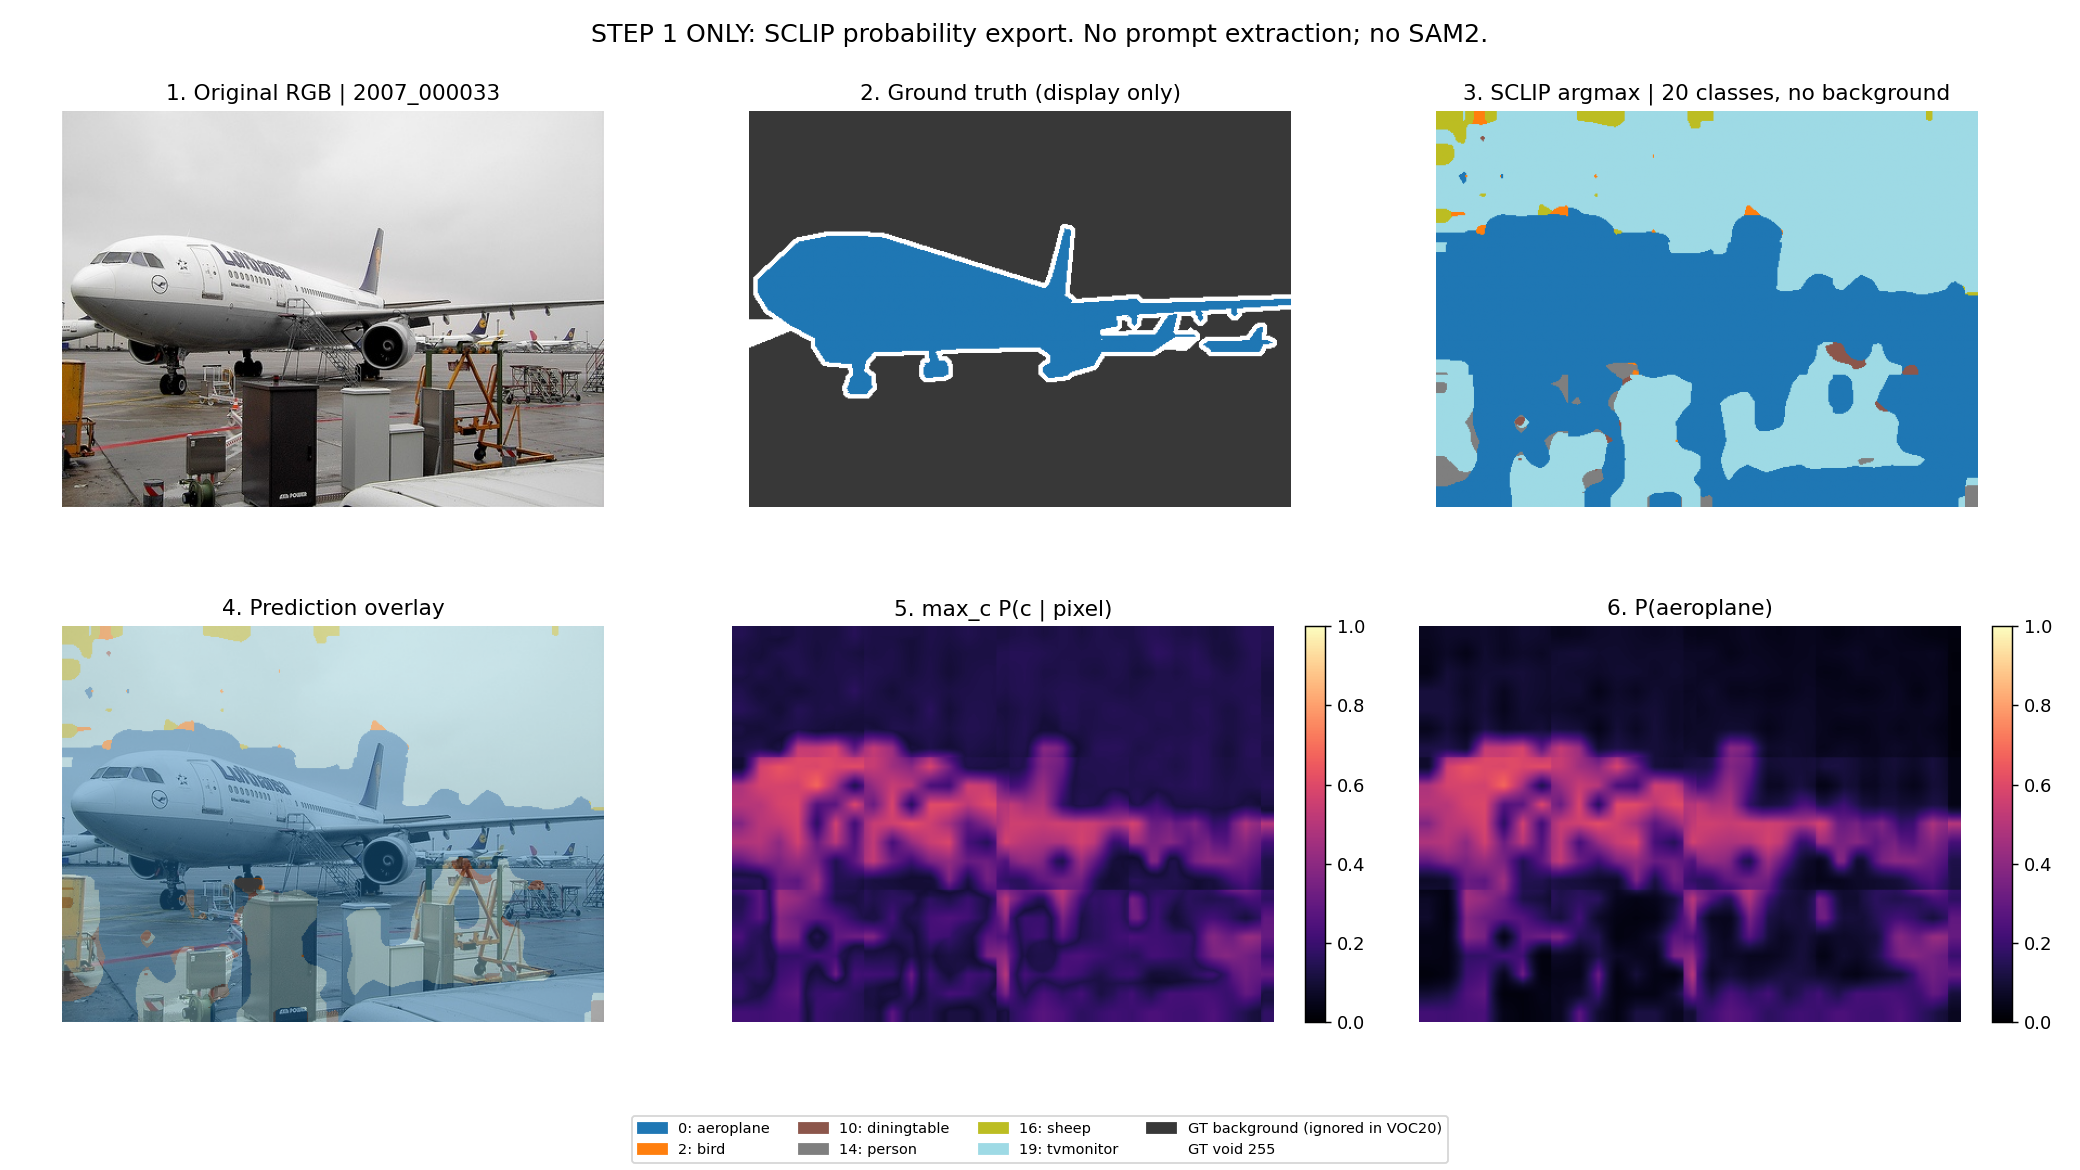

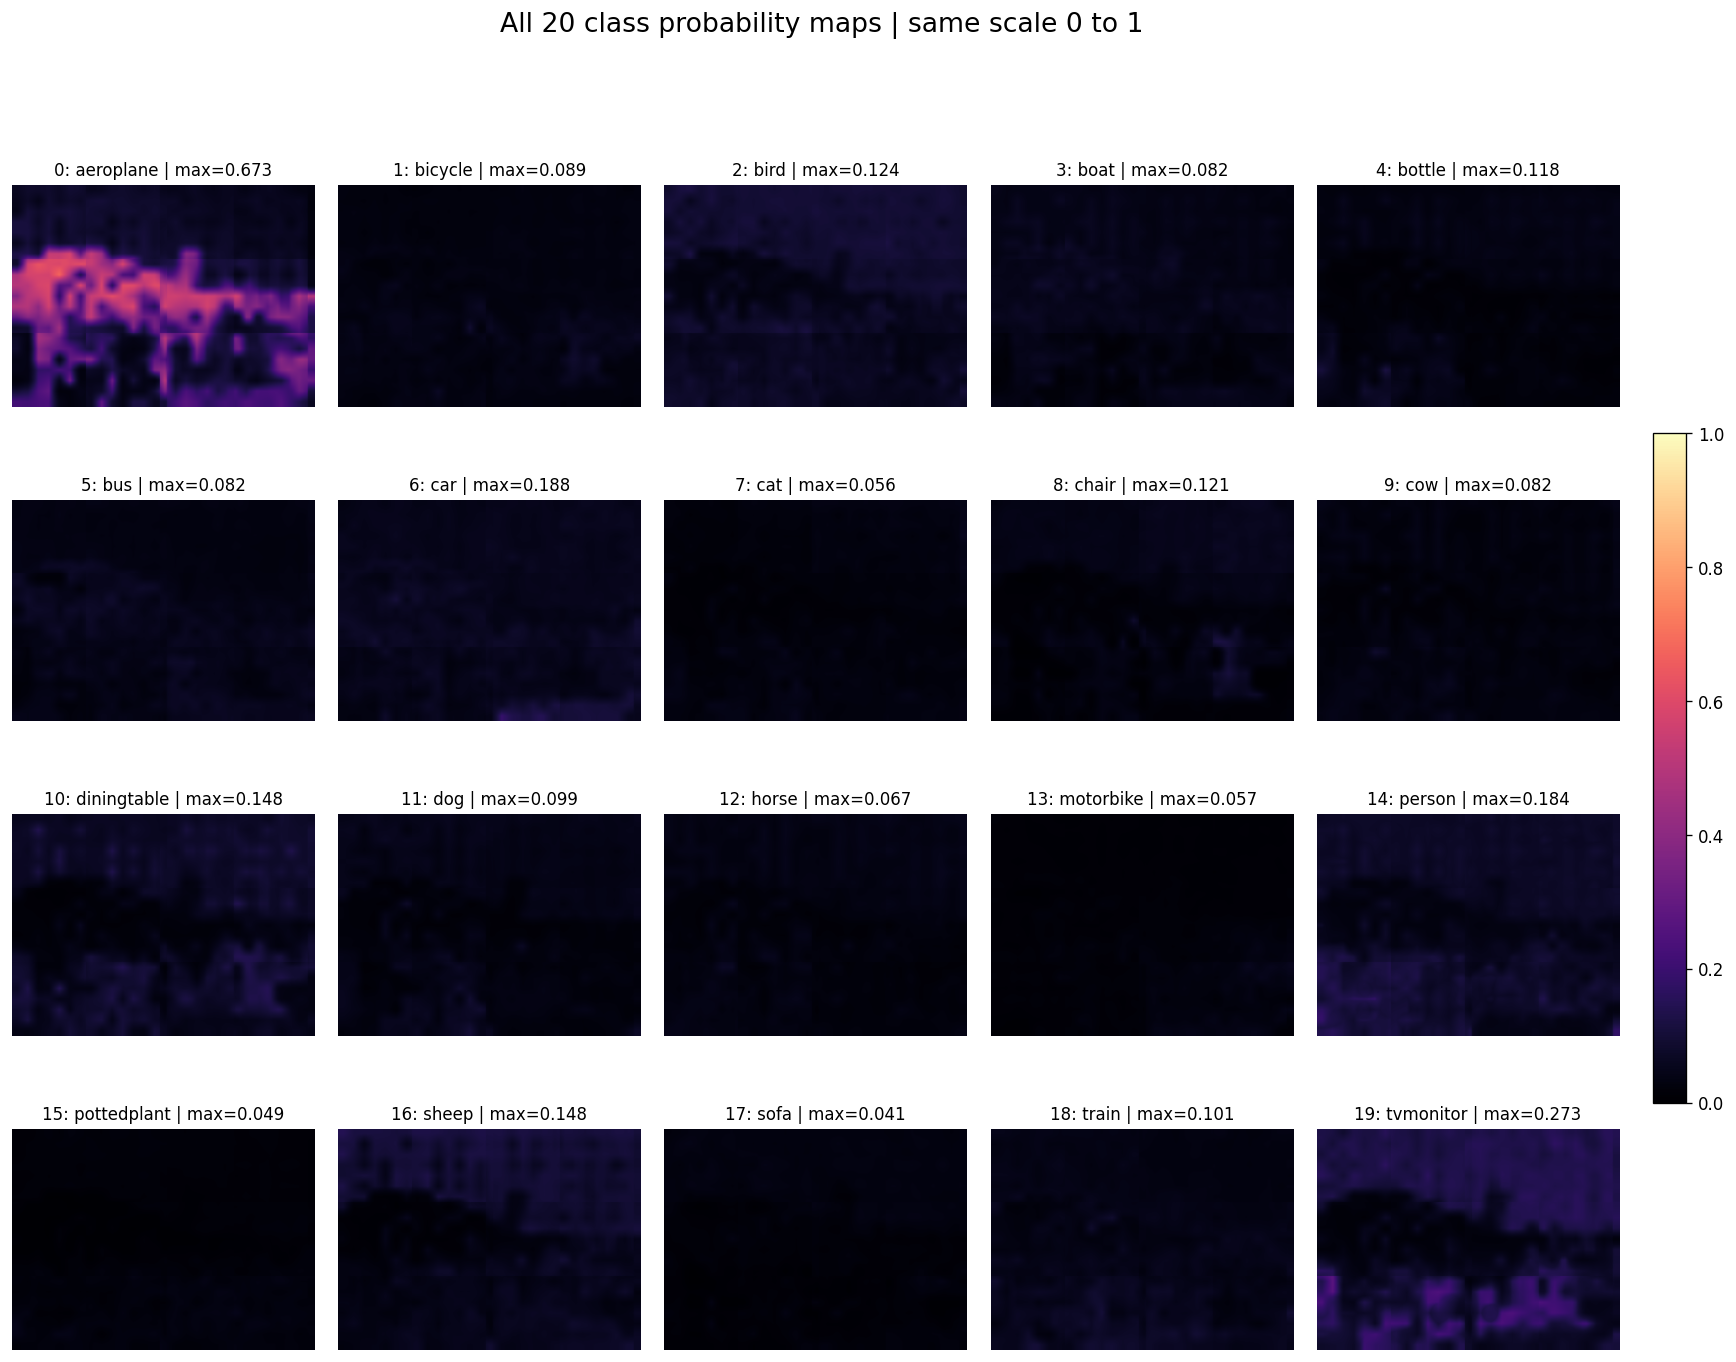

DỪNG Ở BƯỚC 1 — chờ xem kết quả trước khi tạo prompt / chạy SAM2.


In [58]:
# BƯỚC 1: xuất P cho một ảnh. Chưa chạy SAM2.
import os
import subprocess
from pathlib import Path
from IPython.display import display, Image

REPO = Path("/kaggle/working/SCLIP")
PYTHON = "/kaggle/working/sclip-venv/bin/python"
script = r'''import os, sys, json, time, hashlib
from pathlib import Path
os.environ["MPLBACKEND"] = "Agg"
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
from mmengine.config import Config
from mmengine.dataset import pseudo_collate
from mmengine.registry import TRANSFORMS
import mmseg.datasets, mmseg.datasets.transforms, mmseg.models
from mmseg.datasets.transforms import LoadAnnotations, PackSegInputs
from mmseg.registry import DATASETS, MODELS
import custom_datasets, clip_segmentor

OUT = Path("/kaggle/working/SCLIP_RESULTS/step1_export_P")
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = Path("/kaggle/working/SCLIP/runtime_configs/cfg_voc20.py")
TRANSFORMS.register_module(module=LoadAnnotations, name="LoadAnnotations", force=True)
TRANSFORMS.register_module(module=PackSegInputs, name="PackSegInputs", force=True)
cfg = Config.fromfile(str(CONFIG))
dataset = DATASETS.build(cfg.test_dataloader.dataset)
INDEX = 0
sample = dataset[INDEX]
info = dataset.get_data_info(INDEX)
image_path = Path(info["img_path"])
image_id = image_path.stem
rgb = np.asarray(Image.open(image_path).convert("RGB"))
gt_voc = np.asarray(Image.open(info["seg_map_path"]), dtype=np.uint8)
names = list(dataset.metainfo["classes"])
assert len(names) == 20, names
assert torch.cuda.is_available(), "GPU unavailable"
model = MODELS.build(cfg.model).cuda(0).eval()
start = time.perf_counter()
with torch.inference_mode():
    result = model.test_step(pseudo_collate([sample]))[0]
torch.cuda.synchronize()
seconds = time.perf_counter() - start
# Official postprocessing: softmax over text queries, then max over synonyms.
# These are nonnegative class scores, NOT raw logits.
scores = result.seg_logits.data.float().cpu().numpy()
pred = result.pred_sem_seg.data[0].cpu().numpy().astype(np.uint8)
C, H, W = scores.shape
assert (H, W) == rgb.shape[:2] == gt_voc.shape
assert C == len(names) and np.isfinite(scores).all()
assert scores.min() >= 0 and scores.max() <= 1.00001
sum_scores = scores.sum(axis=0, keepdims=True)
assert sum_scores.min() > 0
# Explicit export convention: renormalize max-pooled synonym scores across classes.
# Preserve original scores too, so later experiments can choose transparently.
P = scores / sum_scores
assert np.isfinite(P).all() and np.allclose(P.sum(axis=0), 1, atol=1e-5)
assert np.array_equal(scores.argmax(axis=0), pred)
assert np.array_equal(P.argmax(axis=0), pred)
gt_eval = np.full(gt_voc.shape, 255, dtype=np.uint8)
valid = (gt_voc >= 1) & (gt_voc <= 20)
gt_eval[valid] = gt_voc[valid] - 1
bundle = OUT / (image_id + "_sclip.npz")
np.savez_compressed(bundle, P=P.astype(np.float32),
    class_scores_raw=scores.astype(np.float32), pred=pred,
    image_rgb=rgb, gt_voc=gt_voc, gt_eval=gt_eval,
    class_names=np.array(names), image_id=np.array(image_id))
with np.load(bundle, allow_pickle=False) as reloaded:
    assert np.array_equal(reloaded["P"], P)
    assert np.array_equal(reloaded["pred"], pred)
    assert reloaded["image_rgb"].shape == rgb.shape
palette = np.array(plt.get_cmap("tab20").colors)
pred_rgb = palette[pred]
gt_rgb = np.full((H,W,3), 0.22)
gt_rgb[valid] = palette[gt_eval[valid]]
gt_rgb[gt_voc == 255] = (1,1,1)
conf = P.max(axis=0)
top = np.argsort(np.bincount(pred.ravel(), minlength=C))[::-1]
focus = int(top[0])
fig, axes = plt.subplots(2,3,figsize=(16,9))
axes[0,0].imshow(rgb); axes[0,0].set_title("1. Original RGB | " + image_id)
axes[0,1].imshow(gt_rgb); axes[0,1].set_title("2. Ground truth (display only)")
axes[0,2].imshow(pred_rgb); axes[0,2].set_title("3. SCLIP argmax | 20 classes, no background")
axes[1,0].imshow(rgb); axes[1,0].imshow(pred_rgb, alpha=0.45); axes[1,0].set_title("4. Prediction overlay")
im = axes[1,1].imshow(conf,cmap="magma",vmin=0,vmax=1)
axes[1,1].set_title("5. max_c P(c | pixel)")
fig.colorbar(im,ax=axes[1,1],fraction=0.046)
im = axes[1,2].imshow(P[focus],cmap="magma",vmin=0,vmax=1)
axes[1,2].set_title("6. P(" + names[focus] + ")")
fig.colorbar(im,ax=axes[1,2],fraction=0.046)
for ax in axes.flat: ax.axis("off")
shown = sorted(set(pred.ravel().tolist()) | set(gt_eval[valid].ravel().tolist()))
handles = [Patch(color=palette[c], label=str(c)+": "+names[c]) for c in shown]
handles += [Patch(color=(0.22,0.22,0.22),label="GT background (ignored in VOC20)"),Patch(color="white",label="GT void 255")]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8)
fig.suptitle("STEP 1 ONLY: SCLIP probability export. No prompt extraction; no SAM2.",fontsize=14)
fig.tight_layout(rect=(0,0.10,1,0.96))
fig.subplots_adjust(hspace=0.30)
overview = OUT / (image_id + "_overview.png")
fig.savefig(overview,dpi=130); plt.close(fig)
fig, axes = plt.subplots(4,5,figsize=(18,13))
for c, ax in enumerate(axes.flat):
    im = ax.imshow(P[c],cmap="magma",vmin=0,vmax=1)
    ax.set_title(str(c)+": "+names[c]+" | max="+str(round(float(P[c].max()),3)),fontsize=10)
    ax.axis("off")
fig.suptitle("All 20 class probability maps | same scale 0 to 1",fontsize=16)
fig.subplots_adjust(right=0.90,hspace=0.22,wspace=0.08)
fig.colorbar(im,ax=list(axes.flat),fraction=0.02,pad=0.02)
heatmaps = OUT / (image_id + "_all20_heatmaps.png")
fig.savefig(heatmaps,dpi=120,bbox_inches="tight"); plt.close(fig)
metadata = dict(step=1,image_id=image_id,dataset="VOC20",index=INDEX,
    image_path=str(image_path),shape_CHW=list(P.shape),class_names=names,
    class_id_mapping="prediction 0..19 -> original VOC 1..20; VOC 0 and 255 ignored",
    score_definition="Official query softmax -> max pooling over synonyms",
    P_definition="class_scores_raw / sum(class_scores_raw, axis=0)",
    raw_sum_min=float(sum_scores.min()),raw_sum_max=float(sum_scores.max()),
    P_min=float(P.min()),P_max=float(P.max()),
    sum_P_max_error=float(np.abs(P.sum(0)-1).max()),
    argmax_unchanged=True,roundtrip_passed=True,
    image_sha256=hashlib.sha256(rgb.tobytes()).hexdigest(),
    inference_seconds=seconds,sam2_run=False)
(OUT / (image_id+"_metadata.json")).write_text(json.dumps(metadata,indent=2))
print(json.dumps(metadata,indent=2))
print("Predicted class counts:", {names[c]:int((pred==c).sum()) for c in range(C) if (pred==c).any()})
print("EXPORT P CHECKS PASSED")
print("Bundle:",bundle)
print("Overview:",overview)
print("All class maps:",heatmaps)
'''
env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PYTHONPATH"] = str(REPO) + os.pathsep + env.get("PYTHONPATH", "")
env["TORCH_HOME"] = "/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"] = "/kaggle/working/sclip_home/.cache"
result = subprocess.run([PYTHON, "-c", script], cwd=str(REPO), env=env, capture_output=True, text=True, timeout=300)
print(result.stdout)
if result.stderr:
    print("Diagnostics:", result.stderr[-4000:])
result.check_returncode()
for pattern in ["*_overview.png", "*_all20_heatmaps.png"]:
    path = sorted(Path("/kaggle/working/SCLIP_RESULTS/step1_export_P").glob(pattern))[0]
    display(Image(filename=str(path)))
print("DỪNG Ở BƯỚC 1 — chờ xem kết quả trước khi tạo prompt / chạy SAM2.")


\(P\): 20 lớp × 366 × 500 pixel.
Tổng xác suất mỗi pixel ≈ 1.
Chuẩn hóa giữ nguyên nhãn dự đoán; file xuất đã đọc lại và kiểm tra thành công.
Đã hiển thị ảnh gốc, nhãn thật, dự đoán, ảnh chồng màu và 20 heatmap.

In [59]:
import os, sys, shutil, subprocess
from pathlib import Path
print("DISK", round(shutil.disk_usage("/kaggle/working").free/1024**3,2),"GB")
print("SYSTEM",sys.version)
print("Torch in system:")
subprocess.run([sys.executable,"-c","import torch, torchvision; print(torch.__version__, torchvision.__version__, torch.cuda.is_available())"])
print("WORKING DIRS", [p.name for p in Path("/kaggle/working").iterdir()])
r=Path("/kaggle/working/SCLIP")
print("VOC21 CONFIG", (r/"configs/cfg_voc21.py").read_text())
print("VOC21 CLASSES", (r/"configs/cls_voc21.txt").read_text())


DISK 8.66 GB
SYSTEM 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Torch in system:
2.11.0+cu130 0.26.0+cu130 True
WORKING DIRS ['datasets', 'SCLIP', 'SCLIP_RESULTS', 'sclip-venv', 'sclip_home', '.virtual_documents']
VOC21 CONFIG _base_ = './base_config.py'

# model settings
model = dict(
    name_path='./configs/cls_voc21.txt',
    logit_scale=65,
    prob_thd=0.1,
    area_thd=0.1
)

# dataset settings
dataset_type = 'PascalVOCDataset'
data_root = ''

test_pipeline = [
    dict(type='LoadImageFromFile'),
    dict(type='Resize', scale=(2048, 336), keep_ratio=True),
    dict(type='LoadAnnotations'),
    dict(type='PackSegInputs')
]

test_dataloader = dict(
    batch_size=1,
    num_workers=4,
    persistent_workers=True,
    sampler=dict(type='DefaultSampler', shuffle=False),
    dataset=dict(
        type=dataset_type,
        data_root=data_root,
        data_prefix=dict(
            img_path='JPEGImages', seg_map_path='SegmentationClass'),
        ann_file='ImageSets/Segmentatio

In [60]:
# VOC21: chuẩn bị SAM2, không thay môi trường SCLIP
import os, sys, subprocess
from pathlib import Path
SAM_REPO = Path("/kaggle/working/sam2")
SAM_ENV = Path("/kaggle/working/sam2-venv")
SAM_PY = SAM_ENV / "bin/python"
if not SAM_REPO.exists():
    subprocess.run(["git","clone","https://github.com/facebookresearch/sam2.git",str(SAM_REPO)],check=True)
if not SAM_PY.exists():
    subprocess.run(["uv","venv","--python",sys.executable,"--system-site-packages",str(SAM_ENV)],check=True)
env = os.environ.copy()
env["SAM2_BUILD_CUDA"] = "0"
env["MPLBACKEND"] = "Agg"
subprocess.run(["uv","pip","install","--python",str(SAM_PY),"hydra-core>=1.3.2","iopath","tqdm","pillow","scipy","matplotlib"],env=env,check=True)
subprocess.run(["uv","pip","install","--python",str(SAM_PY),"--no-deps","--no-build-isolation","-e",str(SAM_REPO)],env=env,check=True)
checkpoint = SAM_REPO/"checkpoints/sam2_hiera_tiny.pt"
checkpoint.parent.mkdir(exist_ok=True)
if not checkpoint.exists():
    subprocess.run(["curl","-fL","--retry","2","--connect-timeout","30",
        "https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_tiny.pt","-o",str(checkpoint)],check=True)
print("SAM2 commit:", subprocess.check_output(["git","-C",str(SAM_REPO),"rev-parse","HEAD"],text=True).strip())
subprocess.run([str(SAM_PY),"-c","import torch, sam2, scipy; print('SAM2 READY',torch.__version__,torch.cuda.get_device_name(1)); from sam2.build_sam import build_sam2; m=build_sam2('configs/sam2/sam2_hiera_t.yaml', '/kaggle/working/sam2/checkpoints/sam2_hiera_tiny.pt', device='cuda:1'); print('SAM2 MODEL LOAD PASSED')"],cwd=str(SAM_REPO),env=env,check=True)


Cloning into '/kaggle/working/sam2'...
Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: sam2-venv
Activate with: source sam2-venv/bin/activate
Using Python 3.13.16 environment at: sam2-venv
Resolved 20 packages in 1.19s
Prepared 20 packages in 1.82s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 20 packages in 487ms
 + antlr4-python3-runtime==4.9.3
 + contourpy==1.4.0
 + cycler==0.12.1
 + fonttools==4.68.0
 + hydra-core==1.3.8
 + iopath==0.1.10
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + numpy==2.5.4
 + omegaconf==2.3.1
 + packaging==26.3
 + pillow==13.0.0
 + portalocker==4.4.2
 + pyparsing==3.3.3
 + python-dateutil==4.0.0
 + pyyaml==6.0.3
 + scipy==1.18.1
 + tqdm==4.70.1
 + typing-extensions==4.16.0
 + tzdata==2026.6
Using Python 3.13.16 environment at: sam2-v

SAM2 commit: 2b90b9f5ceec907a1c18123530e92e794ad901a4
SAM2 READY 2.11.0+cu130 Tesla T4
SAM2 MODEL LOAD PASSED


CompletedProcess(args=['/kaggle/working/sam2-venv/bin/python', '-c', "import torch, sam2, scipy; print('SAM2 READY',torch.__version__,torch.cuda.get_device_name(1)); from sam2.build_sam import build_sam2; m=build_sam2('configs/sam2/sam2_hiera_t.yaml', '/kaggle/working/sam2/checkpoints/sam2_hiera_tiny.pt', device='cuda:1'); print('SAM2 MODEL LOAD PASSED')"], returncode=0)

In [61]:
# VOC21: triển khai guided / per_class / verified + kiểm tra nhanh 3 ảnh
import os, sys, subprocess, json
from pathlib import Path
CODE = Path("/kaggle/working/SCLIP_RESULTS/voc21_code_v1")
CODE.mkdir(parents=True, exist_ok=True)
(CODE / "refinement_common.py").write_text("import numpy as np\nfrom scipy import ndimage\n\nC = 21\nMODES = (\"sclip\", \"guided\", \"per_class\", \"verified\")\nTAU = max(0.1, 1 / np.sqrt(C))\nAREA = 10\nIOU = 0.8\nRATIO = 1.0\n\ndef prompts(P, mode):\n    # Class-separated components avoid joining touching different semantic classes.\n    winner = P.argmax(0)\n    out = []\n    for c in range(P.shape[0]):\n        region = P[c] > TAU\n        if mode == \"guided\":\n            region &= winner == c\n        labels, n = ndimage.label(region, structure=np.ones((3,3), dtype=np.uint8))\n        for k, sl in enumerate(ndimage.find_objects(labels), 1):\n            if sl is None:\n                continue\n            yy, xx = np.nonzero(labels[sl] == k)\n            if len(xx) <= AREA:\n                continue\n            yy = yy + sl[0].start\n            xx = xx + sl[1].start\n            cy, cx = yy.mean(), xx.mean()\n            # Nearest member of component; avoids a centroid outside a concave region.\n            j = np.argmin((yy-cy)**2+(xx-cx)**2)\n            x, y = int(xx[j]), int(yy[j])\n            out.append(dict(x=x,y=y,c=c,s=float(P[c,y,x]),area=int(len(xx))))\n    return out\n\ndef verify(mask, P, c):\n    weights = P[:,mask].sum(1,dtype=np.float64)\n    best = int(weights.argmax())\n    if best != c and weights[best] > RATIO * weights[c]:\n        return best\n    return c\n\ndef dedup(items):\n    # Algorithm 1 keeps the higher-confidence mask; does not union mask geometries.\n    kept = []\n    for a in sorted(items, key=lambda a:-a[\"s\"]):\n        mask=a[\"mask\"]\n        area=int(mask.sum())\n        duplicate=False\n        for b in kept:\n            if a[\"c\"] != b[\"c\"]:\n                continue\n            intersection=np.logical_and(mask,b[\"mask\"]).sum()\n            if intersection / max(1, area+int(b[\"mask\"].sum())-intersection) > IOU:\n                duplicate=True\n                break\n        if not duplicate:\n            kept.append(a)\n    return kept\n\ndef compose(items,P,fallback):\n    pred = fallback.copy()\n    covered = np.zeros(fallback.shape,dtype=bool)\n    best = np.full(fallback.shape,-np.inf,dtype=np.float32)\n    # Tie break: smaller class ID, same convention as argmax.\n    for item in sorted(items,key=lambda a:a[\"c\"]):\n        c, mask = item[\"c\"], item[\"mask\"]\n        update=mask & (P[c] > best)\n        pred[update]=c\n        best[update]=P[c,update]\n        covered |= mask\n    return pred, covered\n\ndef confusion(gt,pred,C=21):\n    valid = gt != 255\n    assert ((gt[valid]>=0)&(gt[valid]<C)).all()\n    assert ((pred>=0)&(pred<C)).all()\n    return np.bincount(C*gt[valid].astype(np.int64)+pred[valid],minlength=C*C).reshape(C,C)\n\ndef metrics(cm,names):\n    diag=np.diag(cm).astype(float)\n    gt=cm.sum(1).astype(float); pr=cm.sum(0).astype(float)\n    union=gt+pr-diag\n    iou=np.divide(diag,union,out=np.full(len(gt),np.nan),where=union>0)\n    acc=np.divide(diag,gt,out=np.full(len(gt),np.nan),where=gt>0)\n    return dict(mIoU=float(np.nanmean(iou)*100),mAcc=float(np.nanmean(acc)*100),\n        aAcc=float(diag.sum()/max(1,cm.sum())*100),\n        per_class_IoU={name:(float(x*100) if np.isfinite(x) else None) for name,x in zip(names,iou)},\n        valid_pixels=int(cm.sum()))\n\ndef self_test():\n    P=np.zeros((3,3,3),np.float32);P[0]=.1;P[1]=.7;P[2]=.2\n    whole=np.ones((3,3),bool)\n    assert verify(whole,P,2)==1\n    assert verify(whole,P,1)==1\n    keep=dedup([dict(c=1,s=.8,mask=whole),dict(c=1,s=.6,mask=whole),dict(c=2,s=.5,mask=whole)])\n    assert len(keep)==2\n    fallback=np.zeros((3,3),np.uint8)\n    pred,covered=compose(keep,P,fallback)\n    assert (pred==1).all() and covered.all()\n    pred,covered=compose([],P,fallback)\n    assert np.array_equal(pred,fallback) and not covered.any()\n    cm=confusion(np.array([[0,1,255]]),np.array([[0,0,2]]),3)\n    assert cm.sum()==2 and cm[0,0]==1 and cm[1,0]==1\n    # 8-connectivity keeps diagonal regions connected.\n    a=np.eye(5,dtype=bool)\n    assert ndimage.label(a,np.ones((3,3)))[1]==1\n    p=np.zeros((21,8,8),np.float32);p[0]=.01;p[1,:4,:4]=.9\n    pts=prompts(p,\"guided\")\n    assert len(pts)==1 and pts[0][\"c\"]==1 and pts[0][\"area\"]==16\n    print(\"ALGORITHM AND METRIC CHECKS PASSED\",flush=True)\n", encoding="utf-8")
(CODE / "export_voc21.py").write_text("import os,sys,time,json,traceback\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom PIL import Image\nfrom mmengine.config import Config\nfrom mmengine.dataset import pseudo_collate\nfrom mmengine.registry import TRANSFORMS\nimport mmseg.datasets,mmseg.datasets.transforms,mmseg.models\nfrom mmseg.datasets.transforms import LoadAnnotations,PackSegInputs\nfrom mmseg.registry import MODELS,DATASETS\nimport custom_datasets,clip_segmentor\n\nroot=Path(sys.argv[1]); limit=int(sys.argv[2]); queue=root/\"queue\"\nqueue.mkdir(exist_ok=True,parents=True)\ntorch.manual_seed(0);np.random.seed(0)\ntorch.backends.cudnn.benchmark=False\ntorch.backends.cudnn.deterministic=True\nTRANSFORMS.register_module(module=LoadAnnotations,name=\"LoadAnnotations\",force=True)\nTRANSFORMS.register_module(module=PackSegInputs,name=\"PackSegInputs\",force=True)\ncfg=Config.fromfile(\"/kaggle/working/SCLIP/configs/cfg_voc21.py\")\ncfg.test_dataloader.dataset.data_root=\"/kaggle/working/datasets/VOCdevkit/VOC2012\"\ncfg.dump(str(root/\"cfg_voc21.py\"))\ndataset=DATASETS.build(cfg.test_dataloader.dataset)\nnames=list(dataset.metainfo[\"classes\"])\nassert len(names)==21 and len(dataset)==1449\nmodel=MODELS.build(cfg.model).cuda(0).eval()\nnames_file=root/\"classes.json\"\nnames_file.write_text(json.dumps(names))\nfor i in range(limit):\n    # Bounded intermediate storage: at most 3 images waiting, not 1449 P maps.\n    while len(list(queue.glob(\"*.npz\")))>=3:\n        time.sleep(.1)\n    info=dataset.get_data_info(i)\n    sample=dataset[i]\n    torch.cuda.synchronize()\n    start=time.perf_counter()\n    with torch.inference_mode():\n        result=model.test_step(pseudo_collate([sample]))[0]\n    torch.cuda.synchronize()\n    seconds=time.perf_counter()-start\n    scores=result.seg_logits.data.float().cpu().numpy()\n    pred=result.pred_sem_seg.data[0].cpu().numpy().astype(np.uint8)\n    denom=scores.sum(0,keepdims=True)\n    assert np.isfinite(scores).all() and (denom>0).all()\n    P=scores/denom\n    rgb=np.array(Image.open(info[\"img_path\"]).convert(\"RGB\"))\n    gt=np.array(Image.open(info[\"seg_map_path\"]),dtype=np.uint8)\n    assert P.shape==(21,*gt.shape) and rgb.shape[:2]==gt.shape==pred.shape\n    assert np.allclose(P.sum(0),1,atol=1e-5)\n    # Official baseline can differ from argmax after its prob_thd background rule.\n    tmp=queue/(f\"{i:06}.tmp\")\n    with tmp.open(\"wb\") as f:\n        np.savez(f,P=P.astype(np.float32),baseline=pred,rgb=rgb,gt=gt,\n            image_id=np.array(Path(info[\"img_path\"]).stem),\n            sclip_seconds=np.array(seconds),\n            p_vs_baseline_disagreement=np.array(int((P.argmax(0)!=pred).sum())))\n    tmp.replace(queue/f\"{i:06}.npz\")\n    if i%25==0: print(\"EXPORTED\",i+1,\"/\",limit,flush=True)\n(root/\"producer_done.json\").write_text(json.dumps(dict(images=limit)))\nprint(\"EXPORT COMPLETE\",limit,flush=True)\n", encoding="utf-8")
(CODE / "run_refinement.py").write_text("import os,sys,time,json,csv,traceback\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom PIL import Image\nimport matplotlib\nmatplotlib.use(\"Agg\")\nimport matplotlib.pyplot as plt\nfrom sam2.build_sam import build_sam2\nfrom sam2.sam2_image_predictor import SAM2ImagePredictor\nfrom refinement_common import *\n\nroot=Path(sys.argv[1]);limit=int(sys.argv[2]);queue=root/\"queue\"\nself_test()\ntorch.manual_seed(0);np.random.seed(0)\ntorch.backends.cudnn.benchmark=False\ntorch.backends.cuda.matmul.allow_tf32=False\ntorch.backends.cudnn.allow_tf32=False\nmodel=build_sam2(\"configs/sam2/sam2_hiera_t.yaml\",\n \"/kaggle/working/sam2/checkpoints/sam2_hiera_tiny.pt\",device=\"cuda:1\",\n apply_postprocessing=False)\npredictor=SAM2ImagePredictor(model)\nmatrices={m:np.zeros((21,21),np.int64) for m in MODES}\nrows=[];names=None;wall=time.perf_counter()\npalette=np.array(plt.get_cmap(\"tab20\").colors)\npalette=np.vstack([np.array([[.16,.16,.16]]),palette])\ndef atomic_json(path,obj):\n    tmp=path.with_suffix(\".tmp\")\n    tmp.write_text(json.dumps(obj,indent=2,allow_nan=False));tmp.replace(path)\n\nfor i in range(limit):\n    file=queue/f\"{i:06}.npz\"\n    while not file.exists():\n        time.sleep(.1)\n    if names is None: names=json.loads((root/\"classes.json\").read_text())\n    with np.load(file,allow_pickle=False) as z:\n        P=z[\"P\"];base=z[\"baseline\"];rgb=z[\"rgb\"];gt=z[\"gt\"]\n        image_id=str(z[\"image_id\"]);sclip_time=float(z[\"sclip_seconds\"])\n        disagree=int(z[\"p_vs_baseline_disagreement\"])\n    # Ground truth is only passed to confusion()/visualization after predictions.\n    start=time.perf_counter()\n    sets={mode:prompts(P,mode) for mode in (\"guided\",\"per_class\")}\n    extraction=time.perf_counter()-start\n    allcoords=sorted({(p[\"x\"],p[\"y\"]) for ps in sets.values() for p in ps})\n    torch.cuda.synchronize(1);t=time.perf_counter()\n    with torch.inference_mode():\n        predictor.set_image(rgb)\n    torch.cuda.synchronize(1);encoding=time.perf_counter()-t\n    cache={}\n    t=time.perf_counter()\n    with torch.inference_mode():\n        for j in range(0,len(allcoords),8):\n            coords=allcoords[j:j+8]\n            # Batch of independent single-positive prompts, NOT one multi-point object.\n            points=np.asarray(coords,np.float32).reshape(-1,1,2)\n            labels=np.ones((len(coords),1),np.int32)\n            masks,quality,_=predictor.predict(point_coords=points,point_labels=labels,multimask_output=True)\n            if len(coords)==1 and masks.ndim==3:\n                masks=masks[None];quality=quality[None]\n            assert masks.shape[:2]==(len(coords),3), masks.shape\n            for k,coord in enumerate(coords):\n                best=int(np.argmax(quality[k]))\n                cache[coord]=dict(mask=masks[k,best].astype(bool),quality=float(quality[k,best]))\n    torch.cuda.synchronize(1);decoding=time.perf_counter()-t\n    maps={\"sclip\":base};details={};mode_seconds={}\n    mode_items={}\n    for mode in (\"guided\",\"per_class\",\"verified\"):\n        t=time.perf_counter()\n        ps=sets[\"per_class\" if mode==\"verified\" else mode]\n        items=[];relabels=0\n        for p in ps:\n            candidate=cache[(p[\"x\"],p[\"y\"])]\n            mask=candidate[\"mask\"]\n            if not mask.any():continue\n            c=p[\"c\"]\n            if mode==\"verified\":\n                new=verify(mask,P,c);relabels+=int(new!=c);c=new\n            items.append(dict(mask=mask,c=c,s=p[\"s\"]))\n        items=dedup(items)\n        pred,covered=compose(items,P,base)\n        assert pred.shape==gt.shape and pred.min()>=0 and pred.max()<=20\n        maps[mode]=pred\n        details[mode]=dict(prompts=len(ps),kept=len(items),\n            relabeled=relabels,coverage=float(covered.mean()))\n        mode_items[mode]=items\n        mode_seconds[mode]=time.perf_counter()-t\n    for mode in MODES:\n        matrices[mode]+=confusion(gt,maps[mode])\n    row=dict(index=i,image_id=image_id,sclip_seconds=sclip_time,\n        extraction_seconds=extraction,sam_encode_seconds=encoding,\n        shared_decode_seconds=decoding,unique_points=len(allcoords),\n        p_baseline_disagreement=disagree)\n    for mode in details:\n        for k,v in details[mode].items():row[mode+\"_\"+k]=v\n        row[mode+\"_post_seconds\"]=mode_seconds[mode]\n    rows.append(row)\n    if i<3:\n        fig,ax=plt.subplots(2,4,figsize=(19,9))\n        ax[0,0].imshow(rgb);ax[0,0].set_title(\"RGB \"+image_id)\n        gtshow=palette[np.minimum(gt,20)];gtshow[gt==255]=(1,1,1)\n        ax[0,1].imshow(gtshow);ax[0,1].set_title(\"GT (only for scoring)\")\n        ax[0,2].imshow(P.max(0),vmin=0,vmax=1,cmap=\"magma\");ax[0,2].set_title(\"SCLIP max confidence\")\n        ax[0,3].imshow(rgb)\n        for p in sets[\"per_class\"]:\n            ax[0,3].plot(p[\"x\"],p[\"y\"],\"o\",color=palette[p[\"c\"]],markersize=4)\n        ax[0,3].set_title(\"Per-class prompts: \"+str(len(sets[\"per_class\"])))\n        for k,mode in enumerate(MODES):\n            ax[1,k].imshow(palette[maps[mode]])\n            ax[1,k].set_title(mode+(\" | relabels=\"+str(details[mode][\"relabeled\"]) if mode==\"verified\" else \"\"))\n        for a in ax.flat:a.axis(\"off\")\n        fig.suptitle(\"VOC21: background=0, void=255 ignored | \"+image_id)\n        fig.tight_layout();fig.savefig(root/(image_id+\"_comparison.png\"),dpi=120);plt.close(fig)\n        np.savez_compressed(root/(image_id+\"_predictions.npz\"),gt=gt,**maps)\n    # This removes only the temporary IPC data created for this experiment.\n    file.unlink()\n    progress=dict(status=\"running\",images_completed=i+1,images_total=limit,\n        elapsed_seconds=time.perf_counter()-wall,parameters=dict(tau_conf=float(TAU),area=AREA,iou=IOU,ratio=RATIO),\n        metrics={m:metrics(matrices[m],names) for m in MODES})\n    if (i+1)%10==0 or i+1==limit or i<3:\n        atomic_json(root/\"progress.json\",progress)\n        np.savez(root/\"confusion_matrices.npz\",**matrices)\n        with (root/\"per_image.csv\").open(\"w\",newline=\"\") as f:\n            w=csv.DictWriter(f,fieldnames=rows[0].keys());w.writeheader();w.writerows(rows)\n        print(json.dumps(dict(n=i+1,total=limit,mIoU={m:round(progress[\"metrics\"][m][\"mIoU\"],3) for m in MODES})),flush=True)\nprogress[\"status\"]=\"completed\"\nprogress[\"timing_note\"]=\"Shared image encoding and union-of-points decoding used for three modes; per-mode end-to-end speeds are NOT independently measured.\"\nprogress[\"mean_image_stats\"]={k:float(np.mean([r[k] for r in rows])) for k in rows[0] if k not in (\"index\",\"image_id\")}\nprogress[\"definitions\"]=dict(background_included=True,void_label=255,\n    probability=\"official postprocessed class scores renormalized across 21 classes\",\n    fallback=\"official VOC21 SCLIP prediction\",same_class_filter=\"confidence-ordered suppression, not union\",\n    centroid=\"nearest component member to centroid\",sam_multimask=\"highest SAM predicted IoU; no ground truth\",\n    sam_precision=\"FP32\",sam_postprocessing=False)\natomic_json(root/\"metrics.json\",progress)\natomic_json(root/\"progress.json\",progress)\nprint(\"ALL IMAGES COMPLETE\",limit,flush=True)\n", encoding="utf-8")
(CODE / "supervisor.py").write_text("import os,sys,time,json,subprocess,hashlib\nfrom pathlib import Path\nroot=Path(sys.argv[1]);limit=int(sys.argv[2]);code=Path(__file__).parent\nroot.mkdir(parents=True,exist_ok=True)\nenv=os.environ.copy();env[\"MPLBACKEND\"]=\"Agg\";env[\"PYTHONUNBUFFERED\"]=\"1\"\nenv[\"TORCH_HOME\"]=\"/kaggle/working/sclip_home/.torch\"\nenv[\"XDG_CACHE_HOME\"]=\"/kaggle/working/sclip_home/.cache\"\nenv[\"PYTHONPATH\"]=str(code)+os.pathsep+\"/kaggle/working/SCLIP\"+os.pathsep+env.get(\"PYTHONPATH\",\"\")\nmanifest=dict(images=limit,split=\"VOC2012/ImageSets/Segmentation/val.txt\",\n sclip_commit=subprocess.check_output([\"git\",\"-C\",\"/kaggle/working/SCLIP\",\"rev-parse\",\"HEAD\"],text=True).strip(),\n sam2_commit=subprocess.check_output([\"git\",\"-C\",\"/kaggle/working/sam2\",\"rev-parse\",\"HEAD\"],text=True).strip(),\n sam2_checkpoint=\"sam2_hiera_tiny.pt (SAM2 July 2024)\",\n checkpoint_sha256=hashlib.sha256(Path(\"/kaggle/working/sam2/checkpoints/sam2_hiera_tiny.pt\").read_bytes()).hexdigest(),\n script_sha256={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in code.glob(\"*.py\")})\n(root/\"manifest.json\").write_text(json.dumps(manifest,indent=2))\nprocs=[]\ntry:\n    for name,python,script in [\n      (\"export\",\"/kaggle/working/sclip-venv/bin/python\",\"export_voc21.py\"),\n      (\"refine\",\"/kaggle/working/sam2-venv/bin/python\",\"run_refinement.py\")]:\n        f=(root/(name+\".log\")).open(\"w\")\n        p=subprocess.Popen([python,str(code/script),str(root),str(limit)],\n          cwd=\"/kaggle/working/SCLIP\",env=env,stdout=f,stderr=subprocess.STDOUT)\n        f.close();procs.append(p)\n    (root/\"pids.json\").write_text(json.dumps([p.pid for p in procs]))\n    while any(p.poll() is None for p in procs):\n        failed=[p for p in procs if p.poll() not in (None,0)]\n        if failed:raise RuntimeError(\"Worker failed: \"+str([(p.pid,p.poll()) for p in failed]))\n        time.sleep(2)\n    if any(p.returncode!=0 for p in procs):raise RuntimeError(\"Worker failed\")\n    result=json.loads((root/\"metrics.json\").read_text())\n    assert result[\"images_completed\"]==limit and result[\"status\"]==\"completed\"\n    import shutil\n    shutil.make_archive(str(root)+\"_results\",\"zip\",root_dir=root)\n    (root/\"DONE\").write_text(\"exit_code=0\")\nexcept Exception as e:\n    (root/\"FAILED\").write_text(repr(e))\n    for p in procs:\n        if p.poll() is None:p.terminate()\n    raise\n", encoding="utf-8")
RUN = Path("/kaggle/working/SCLIP_RESULTS/voc21_smoke_v1")
assert not (RUN / "pids.json").exists(), "Lượt smoke đã có; xem trạng thái, không chạy trùng."
RUN.mkdir(parents=True,exist_ok=True)
env=os.environ.copy(); env["MPLBACKEND"]="Agg"
log=(RUN/"supervisor.log").open("w")
proc=subprocess.Popen([sys.executable,str(CODE/"supervisor.py"),str(RUN),"3"],env=env,stdout=log,stderr=subprocess.STDOUT,start_new_session=True)
log.close()
print("SMOKE STARTED",proc.pid,RUN)
print("Chưa chạy toàn tập; kiểm tra smoke trước.")


SMOKE STARTED 832 /kaggle/working/SCLIP_RESULTS/voc21_smoke_v1
Chưa chạy toàn tập; kiểm tra smoke trước.


In [63]:
# Theo dõi VOC21 (chạy lại riêng ô này để cập nhật, không chạy Run All)
from pathlib import Path
import json
from IPython.display import display, Image
RUN=Path("/kaggle/working/SCLIP_RESULTS/voc21_smoke_v1")
for name in ["FAILED","DONE","progress.json"]:
    p=RUN/name
    if p.exists(): print(name, p.read_text()[-16000:])
for name in ["export.log","refine.log","supervisor.log"]:
    p=RUN/name
    if p.exists(): print("\\n"+name+"\\n"+p.read_text(errors="replace")[-5000:])
if (RUN/"DONE").exists():
    for p in sorted(RUN.glob("*_comparison.png")): display(Image(filename=str(p)))


\nexport.log\n
\nrefine.log\nALGORITHM AND METRIC CHECKS PASSED

\nsupervisor.log\n


In [64]:
# VOC21 TOÀN TẬP — chạy một lần; dùng ô trạng thái phía dưới để theo dõi
import os, sys, json, subprocess
from pathlib import Path
CODE=Path("/kaggle/working/SCLIP_RESULTS/voc21_code_v1")
SMOKE=Path("/kaggle/working/SCLIP_RESULTS/voc21_smoke_v1")
# FIX 2026-11-04 [VOC21 full launch]: wait for asynchronous smoke supervisor before checking DONE.
import time
smoke_deadline = time.monotonic() + 600
while not (SMOKE/"DONE").exists():
    if (SMOKE/"FAILED").exists():
        raise RuntimeError((SMOKE/"FAILED").read_text() + " | See smoke export/refine logs")
    if time.monotonic() > smoke_deadline:
        raise TimeoutError("Smoke test did not finish within 600 seconds")
    time.sleep(2)
RUN=Path("/kaggle/working/SCLIP_RESULTS/voc21_full_v1")
assert not (RUN/"pids.json").exists(), "Đã khởi chạy; không chạy trùng"
RUN.mkdir(parents=True,exist_ok=True)
env=os.environ.copy();env["MPLBACKEND"]="Agg"
log=(RUN/"supervisor.log").open("w")
full_proc=subprocess.Popen([sys.executable,str(CODE/"supervisor.py"),str(RUN),"1449"],
    env=env,stdout=log,stderr=subprocess.STDOUT,start_new_session=True)
log.close()
(RUN/"supervisor_pid.txt").write_text(str(full_proc.pid))
print("VOC21 FULL STARTED",full_proc.pid)
print("All modes: sclip, guided, per_class, verified")
print("Results:",RUN)


VOC21 FULL STARTED 862
All modes: sclip, guided, per_class, verified
Results: /kaggle/working/SCLIP_RESULTS/voc21_full_v1


In [66]:
# CẬP NHẬT TIẾN ĐỘ VOC21 — không khởi chạy lại
from pathlib import Path
import json, os
import pandas as pd
from IPython.display import display, Image, FileLink
RUN=Path("/kaggle/working/SCLIP_RESULTS/voc21_full_v1")
p=RUN/"progress.json"
if (RUN/"FAILED").exists():
    print("FAILED", (RUN/"FAILED").read_text())
    for name in ["refine.log","export.log","supervisor.log"]:
        f=RUN/name
        if f.exists():print(name, f.read_text(errors="replace")[-6000:])
elif p.exists():
    result=json.loads(p.read_text())
    n,total=result["images_completed"],result["images_total"]
    elapsed=result["elapsed_seconds"]
    print("STATUS:",result["status"],"|",n,"/",total,"ảnh")
    print("Elapsed:",round(elapsed/60,2),"min | ETA:",round(elapsed/max(n,1)*(total-n)/60,2),"min")
    table=pd.DataFrame({m:{k:v[k] for k in ["mIoU","mAcc","aAcc"]} for m,v in result["metrics"].items()}).T
    print(table.round(3).to_string())
    print("Background included; ignore label 255; confusion matrices aggregated over processed images.")
    if result["status"]=="completed":
        assert n==1449
        assert (RUN/"DONE").exists(), "Supervisor đang hoàn tất gói kết quả"
        print("ALL 1449 IMAGES COMPLETE — exit code 0")
        print("Metrics:",RUN/"metrics.json")
        print("Per-image CSV:",RUN/"per_image.csv")
        print("Archive:",str(RUN)+"_results.zip")
else:
    print("Đang khởi tạo mô hình; chưa có checkpoint tiến độ.")


STATUS: running | 3 / 1449 ảnh
Elapsed: 0.2 min | ETA: 97.93 min
             mIoU    mAcc    aAcc
sclip      52.619  85.937  82.865
guided     38.180  61.501  51.181
per_class  28.386  56.367  37.612
verified   55.125  87.815  83.891
Background included; ignore label 255; confusion matrices aggregated over processed images.


In [68]:
from pathlib import Path
import json

BASE = Path("/kaggle/working/SCLIP_RESULTS")
ROOT = BASE / "voc21_full_v1"
SMOKE = BASE / "voc21_smoke_v1"
CODE = BASE / "voc21_code_v1"


def show_logs(folder):
    for name in ["supervisor.log", "export.log", "refine.log"]:
        path = folder / name
        if path.is_file():
            print(f"\n--- {path.name} ---")
            print(path.read_text(errors="replace")[-5000:])


def check_status():
    print("Thư mục kết quả:", ROOT)

    if (ROOT / "FAILED").exists():
        print("\nSCLIP + SAM2 đã báo lỗi:")
        print((ROOT / "FAILED").read_text(errors="replace"))
        show_logs(ROOT)
        return

    if (ROOT / "DONE").exists() and (ROOT / "metrics.json").is_file():
        data = json.loads((ROOT / "metrics.json").read_text())
        print("\nĐã có kết quả.")
        print("Trạng thái:", data.get("status"))
        print("Số ảnh:", data.get("images_completed"))
        print("Có thể chạy cell tổng hợp.")
        return

    progress = ROOT / "progress.json"
    if progress.is_file():
        try:
            data = json.loads(progress.read_text())
            print("\nTiến độ đã lưu:")
            print("Trạng thái:", data.get("status"))
            print(
                "Số ảnh:",
                data.get("images_completed"),
                "/",
                data.get("images_total"),
            )
            print(
                "Chưa có kết quả hoàn tất. "
                "Tiến độ đã lưu chưa chứng minh tiến trình vẫn đang chạy."
            )
        except json.JSONDecodeError:
            print("Chưa đọc được progress.json.")
        show_logs(ROOT)
        return

    # Đã có dấu vết khởi chạy: xem log trước, không chạy lại ngay.
    if ROOT.exists() and any(
        (ROOT / name).exists()
        for name in ["pids.json", "supervisor.log", "export.log", "refine.log"]
    ):
        print("\nĐã có dấu vết khởi chạy nhưng chưa có tiến độ.")
        print("Xem log dưới đây để xác định đang khởi tạo hay gặp lỗi.")
        show_logs(ROOT)
        return

    if (SMOKE / "FAILED").exists():
        print("\nSmoke test bị lỗi:")
        print((SMOKE / "FAILED").read_text(errors="replace"))
        show_logs(SMOKE)
        return

    if not (CODE / "supervisor.py").is_file():
        print("\nChưa có script chạy SCLIP + SAM2.")
        print("Chạy cell chuẩn bị SAM2, rồi cell tạo voc21_code_v1.")
        return

    if not (SMOKE / "DONE").exists():
        print("\nSmoke test chưa được xác nhận hoàn tất.")
        print("Kiểm tra cell SMOKE STARTED và cell theo dõi smoke.")
        show_logs(SMOKE)
        return

    print("\nSmoke test đã hoàn tất; chưa thấy dấu vết lượt chạy toàn tập.")
    print("Bước tiếp theo: chạy cell bắt đầu bằng '# VOC21 TOÀN TẬP'.")


check_status()

Thư mục kết quả: /kaggle/working/SCLIP_RESULTS/voc21_full_v1

Tiến độ đã lưu:
Trạng thái: running
Số ảnh: 20 / 1449
Chưa có kết quả hoàn tất. Tiến độ đã lưu chưa chứng minh tiến trình vẫn đang chạy.

--- supervisor.log ---


--- export.log ---
EXPORTED 1 / 1449


--- refine.log ---
ALGORITHM AND METRIC CHECKS PASSED
{"n": 1, "total": 1449, "mIoU": {"sclip": 38.313, "guided": 44.277, "per_class": 39.974, "verified": 36.29}}
{"n": 2, "total": 1449, "mIoU": {"sclip": 44.591, "guided": 28.22, "per_class": 25.775, "verified": 46.87}}
{"n": 3, "total": 1449, "mIoU": {"sclip": 52.619, "guided": 38.18, "per_class": 28.386, "verified": 55.125}}
{"n": 10, "total": 1449, "mIoU": {"sclip": 60.471, "guided": 45.774, "per_class": 33.273, "verified": 68.578}}
{"n": 20, "total": 1449, "mIoU": {"sclip": 46.719, "guided": 38.511, "per_class": 26.196, "verified": 53.607}}



In [69]:
import json
import hashlib
import shutil
import zipfile
import re
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

BASE = Path("/kaggle/working/SCLIP_RESULTS")
ROOT = BASE / "voc21_full_v1"
CODE = BASE / "voc21_code_v1"


def show_logs():
    for name in ["supervisor.log", "export.log", "refine.log"]:
        path = ROOT / name
        if path.is_file():
            print(f"\n--- {name} ---")
            print(path.read_text(errors="replace")[-3000:])


def main():
    # 1. Kiểm tra lỗi của lượt chạy.
    failed = ROOT / "FAILED"

    if failed.is_file():
        print("SCLIP + SAM2 đã báo lỗi:")
        print(failed.read_text(errors="replace"))
        show_logs()
        return

    # 2. Chỉ đọc metrics.json khi đã hoàn tất.
    metrics_path = ROOT / "metrics.json"
    done_path = ROOT / "DONE"

    if not (metrics_path.is_file() and done_path.is_file()):
        print("SCLIP + SAM2 chưa được xác nhận hoàn tất.")

        progress_path = ROOT / "progress.json"

        if progress_path.is_file():
            try:
                progress = json.loads(progress_path.read_text())
            except json.JSONDecodeError:
                print("Chưa đọc được progress.json. Chạy lại cell sau.")
                return

            n = progress.get("images_completed", 0)
            total = progress.get("images_total", 0)

            print("Trạng thái đã lưu:", progress.get("status"))
            print(f"Tiến độ đã lưu: {n}/{total} ảnh")

            if total:
                print(f"Hoàn thành: {100 * n / total:.1f}%")

            if progress.get("metrics"):
                table = pd.DataFrame({
                    mode: {
                        key: values.get(key)
                        for key in ["mIoU", "mAcc", "aAcc"]
                    }
                    for mode, values in progress["metrics"].items()
                }).T

                print("\nMetric tạm thời (%):")
                display(table.round(3))
        else:
            print("Chưa tìm thấy progress.json.")
            show_logs()

        print("\nChạy lại cell này sau để kiểm tra kết quả.")
        print("Cell này không khởi chạy lại mô hình.")
        return

    # 3. Đọc kết quả cuối.
    r = json.loads(metrics_path.read_text())

    assert r.get("status") == "completed", (
        "metrics.json chưa có trạng thái completed."
    )

    total = int(r["images_total"])
    completed = int(r["images_completed"])

    assert completed == total == 1449, (
        f"Chưa đủ VOC21 validation: {completed}/{total} ảnh."
    )

    for name in [
        "per_image.csv",
        "confusion_matrices.npz",
        "manifest.json",
    ]:
        assert (ROOT / name).is_file(), f"Thiếu file: {ROOT / name}"

    rows = pd.read_csv(
        ROOT / "per_image.csv",
        dtype={"image_id": str},
    )

    assert len(rows) == total, "Số dòng per_image.csv không khớp."
    assert rows["image_id"].notna().all(), "Có image_id bị thiếu."
    assert rows["image_id"].nunique() == total, "Có image_id trùng."

    # 4. Kiểm chứng mIoU bằng confusion matrix.
    with np.load(ROOT / "confusion_matrices.npz") as matrices:
        assert "sclip" in matrices.files
        assert set(matrices.files) == set(r["metrics"]), (
            "Danh sách biến thể không khớp với metrics.json."
        )

        reference = matrices["sclip"].sum(axis=1)

        for mode in matrices.files:
            cm = matrices[mode]

            assert cm.shape == (21, 21), (
                f"{mode}: confusion matrix không có kích thước 21x21."
            )
            assert np.isfinite(cm).all() and (cm >= 0).all(), (
                f"{mode}: confusion matrix có giá trị không hợp lệ."
            )

            assert np.array_equal(cm.sum(axis=1), reference), (
                f"{mode}: số pixel ground truth không khớp."
            )

            diagonal = np.diag(cm).astype(float)
            union = cm.sum(axis=0) + cm.sum(axis=1) - diagonal

            iou = np.divide(
                diagonal,
                union,
                out=np.full(diagonal.shape, np.nan),
                where=union > 0,
            )

            recomputed_miou = float(np.nanmean(iou) * 100)
            saved_miou = float(r["metrics"][mode]["mIoU"])

            assert np.isclose(
                recomputed_miou,
                saved_miou,
                atol=1e-8,
                rtol=0,
            ), (
                f"{mode}: mIoU không khớp. "
                f"Tính lại={recomputed_miou}, đã lưu={saved_miou}"
            )

    # 5. Kiểm chứng mã nguồn theo manifest.
    manifest = json.loads((ROOT / "manifest.json").read_text())
    hashes = manifest.get("script_sha256", {})
    assert hashes, "Manifest không chứa hash mã nguồn."

    verified_code_dir = None

    for candidate in [ROOT / "code", CODE]:
        matches = all(
            (candidate / name).is_file()
            and hashlib.sha256(
                (candidate / name).read_bytes()
            ).hexdigest() == expected_hash
            for name, expected_hash in hashes.items()
        )

        if matches:
            verified_code_dir = candidate
            break

    assert verified_code_dir is not None, (
        "Không tìm thấy mã nguồn khớp manifest. "
        "Kiểm tra xem code có bị sửa sau khi bắt đầu chạy không."
    )

    # 6. Tìm baseline VOC21 đã hoàn tất.
    official_miou = None
    official_source = None

    baseline_paths = [
        ROOT / "official_baseline.log",
        BASE / "logs" / "voc21.log",
    ]

    for path in baseline_paths:
        if not path.is_file():
            continue

        text = path.read_text(errors="replace")
        text = re.sub(r"\x1b\[[0-?]*[ -/]*[@-~]", "", text)
        candidates = []

        for line in text.splitlines():
            progress = re.search(
                r"\[\s*(\d+)\s*/\s*(\d+)\s*\]",
                line,
            )
            metric = re.search(
                r"\bmIoU:\s*([0-9]+(?:\.[0-9]+)?)",
                line,
            )

            if progress and metric:
                n, count = map(int, progress.groups())
                if n == count == total:
                    candidates.append(float(metric.group(1)))

        if candidates:
            official_miou = candidates[-1]
            official_source = path
            break

    difference = None
    baseline_verified = False

    if official_miou is not None:
        difference = abs(
            official_miou - float(r["metrics"]["sclip"]["mIoU"])
        )

        assert difference < 0.15, (
            f"Baseline lệch {difference:.4f} điểm phần trăm, "
            "vượt ngưỡng 0.15. Cần kiểm tra config và log baseline."
        )

        baseline_verified = True
        destination = ROOT / "official_baseline.log"

        if official_source != destination:
            shutil.copy2(official_source, destination)
    else:
        print(
            "Chưa có log baseline hoàn tất. "
            "Kết quả sẽ được lưu với trạng thái chưa đối chiếu baseline."
        )

    # 7. Lưu báo cáo kiểm chứng.
    verification = {
        "images": total,
        "unique_images": int(rows["image_id"].nunique()),
        "valid_pixels": int(reference.sum()),
        "mIoU_recomputed": True,
        "identical_ground_truth_counts": True,
        "source_hashes_verified": True,
        "official_baseline_verified": baseline_verified,
        "official_sclip_mIoU": official_miou,
        "baseline_difference_pp": difference,
        "official_baseline_source": (
            str(official_source) if official_source else None
        ),
    }

    (ROOT / "validation.json").write_text(
        json.dumps(verification, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    if verified_code_dir != ROOT / "code":
        shutil.copytree(
            verified_code_dir,
            ROOT / "code",
            dirs_exist_ok=True,
            ignore=shutil.ignore_patterns("__pycache__"),
        )

    # 8. Lưu bảng tổng hợp.
    table = pd.DataFrame({
        mode: {
            key: values[key]
            for key in ["mIoU", "mAcc", "aAcc"]
        }
        for mode, values in r["metrics"].items()
    }).T

    table["delta_mIoU_pp"] = (
        table["mIoU"] - table.loc["sclip", "mIoU"]
    )

    table.to_csv(
        ROOT / "summary.csv",
        index_label="variant",
        encoding="utf-8-sig",
    )

    perclass = pd.DataFrame({
        mode: values["per_class_IoU"]
        for mode, values in r["metrics"].items()
    })

    perclass.to_csv(
        ROOT / "per_class_IoU.csv",
        index_label="class",
        encoding="utf-8-sig",
    )

    # 9. Đóng gói kết quả; ZIP nằm ngoài ROOT.
    archive = shutil.make_archive(
        str(ROOT) + "_results",
        "zip",
        root_dir=ROOT,
    )

    with zipfile.ZipFile(archive) as package:
        assert package.testzip() is None, "Kiểm tra ZIP thất bại."

    # 10. Hiển thị kết quả thực tế.
    print(f"\nVOC21 HOÀN TẤT: {completed}/{total} ảnh")
    print("\nBảng kết quả (%):")
    display(table.round(3))

    if "verified" in table.index:
        print(
            "Chênh lệch verified so với SCLIP:",
            round(float(table.loc["verified", "delta_mIoU_pp"]), 3),
            "điểm phần trăm",
        )

    print("Đã đối chiếu baseline:", baseline_verified)

    if baseline_verified:
        print("Baseline từ log:", official_miou)
        print("Chênh lệch baseline:", round(difference, 5), "điểm phần trăm")

    print("Tham số:", r.get("parameters", {}))
    print(
        "Thời gian dùng chung tính toán:",
        round(r["elapsed_seconds"] / 60, 2),
        "phút",
    )
    print("Thư mục kết quả:", ROOT)
    print("File ZIP:", archive)
    print("Dung lượng ZIP:", round(Path(archive).stat().st_size / 1e6, 2), "MB")


main()

SCLIP + SAM2 chưa được xác nhận hoàn tất.
Trạng thái đã lưu: running
Tiến độ đã lưu: 30/1449 ảnh
Hoàn thành: 2.1%

Metric tạm thời (%):


,mIoU,mAcc,aAcc
sclip,48.402,70.855,82.257
guided,39.832,64.455,64.237
per_class,27.118,56.325,47.272
verified,53.491,75.437,84.842



Chạy lại cell này sau để kiểm tra kết quả.
Cell này không khởi chạy lại mô hình.


In [ ]:
# # VOC21: kết quả đã kiểm chứng và gói tái lập (không chạy lại mô hình)
# import json,hashlib,shutil,zipfile,re
# from pathlib import Path
# import numpy as np
# import pandas as pd
# from IPython.display import display,Image
# ROOT=Path("/kaggle/working/SCLIP_RESULTS/voc21_full_v1")
# CODE=Path("/kaggle/working/SCLIP_RESULTS/voc21_code_v1")
# r=json.loads((ROOT/"metrics.json").read_text())
# rows=pd.read_csv(ROOT/"per_image.csv")
# assert (ROOT/"DONE").exists() and r["images_completed"]==1449
# assert len(rows)==1449 and rows.image_id.nunique()==1449
# z=np.load(ROOT/"confusion_matrices.npz")
# reference=z["sclip"].sum(1)
# for mode in z.files:
#     cm=z[mode]
#     assert np.array_equal(cm.sum(1),reference), "Ground-truth pixel counts differ"
#     diag=np.diag(cm).astype(float);union=cm.sum(0)+cm.sum(1)-diag
#     miou=np.mean(diag/union)*100
#     assert abs(miou-r["metrics"][mode]["mIoU"])<1e-8
# manifest=json.loads((ROOT/"manifest.json").read_text())
# for name,sha in manifest["script_sha256"].items():
#     assert hashlib.sha256((CODE/name).read_bytes()).hexdigest()==sha
# official=(ROOT/"official_baseline.log").read_text(errors="replace")
# matches=re.findall(r"\[1449/1449\].*?mIoU:\s*([\d.]+)",official)
# assert matches, "Official baseline not complete"
# official_miou=float(matches[-1])
# difference=abs(official_miou-r["metrics"]["sclip"]["mIoU"])
# assert difference<0.15
# verification=dict(images=1449,unique_images=int(rows.image_id.nunique()),
#     valid_pixels=int(reference.sum()),confusion_metrics_recomputed=True,
#     identical_ground_truth_counts=True,source_hashes_verified=True,
#     official_sclip_mIoU=official_miou,baseline_difference_pp=difference)
# (ROOT/"validation.json").write_text(json.dumps(verification,indent=2))
# shutil.copytree(CODE,ROOT/"code",dirs_exist_ok=True,ignore=shutil.ignore_patterns("__pycache__"))
# table=pd.DataFrame({m:{k:v[k] for k in ["mIoU","mAcc","aAcc"]} for m,v in r["metrics"].items()}).T
# table["delta_mIoU_pp"]=table.mIoU-table.loc["sclip","mIoU"]
# table.to_csv(ROOT/"summary.csv",index_label="variant")
# perclass=pd.DataFrame({m:v["per_class_IoU"] for m,v in r["metrics"].items()})
# perclass.to_csv(ROOT/"per_class_IoU.csv",index_label="class")
# archive=shutil.make_archive(str(ROOT)+"_results","zip",root_dir=ROOT)
# with zipfile.ZipFile(archive) as f: assert f.testzip() is None
# print("VOC21 COMPLETE: 1449 / 1449 images — exit code 0")
# print(table.round(3).to_string())
# print("verified improvement:",round(table.loc["verified","delta_mIoU_pp"],3),"percentage points")
# print("Official baseline:",official_miou,"| difference:",round(difference,5),"pp")
# print("CHECKS PASSED: image IDs, confusion matrices, source hashes, ZIP integrity")
# print("SAM2 Hiera-T | no DenseCRF | tau=0.2182, area=10, IoU=0.8, ratio=1.0")
# print("Elapsed all variants:",round(r["elapsed_seconds"]/60,2),"min (shared computation)")
# print("Results:",ROOT)
# print("Archive:",archive,"|",round(Path(archive).stat().st_size/1e6,2),"MB")


In [ ]:
# Đối chiếu baseline VOC21 với evaluator chính thức của SCLIP
import os,subprocess
from pathlib import Path
ROOT=Path("/kaggle/working/SCLIP_RESULTS/voc21_full_v1")
env=os.environ.copy()
env["MPLBACKEND"]="Agg"
env["PYTHONPATH"]="/kaggle/working/SCLIP"
env["TORCH_HOME"]="/kaggle/working/sclip_home/.torch"
env["XDG_CACHE_HOME"]="/kaggle/working/sclip_home/.cache"
log=(ROOT/"official_baseline.log").open("w")
baseline_proc=subprocess.Popen(
 ["/kaggle/working/sclip-venv/bin/python","bootstrap_eval.py",
 "--config",str(ROOT/"cfg_voc21.py"),
 "--work-dir",str(ROOT/"official_baseline")],
 cwd="/kaggle/working/SCLIP",env=env,stdout=log,stderr=subprocess.STDOUT)
log.close()
print("Official VOC21 baseline check started",baseline_proc.pid)


In [ ]:
# KẾT QUẢ CUỐI VOC21 — chỉ đọc; không khởi chạy mô hình
from pathlib import Path
import json,re,zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=Path("/kaggle/working/SCLIP_RESULTS/voc21_full_v1")
if not (ROOT/"DONE").exists():
    print("Chưa hoàn tất; xem ô cập nhật tiến độ.")
else:
    r=json.loads((ROOT/"metrics.json").read_text())
    assert r["status"]=="completed" and r["images_completed"]==1449
    rows=pd.read_csv(ROOT/"per_image.csv")
    assert len(rows)==1449 and rows.image_id.nunique()==1449
    z=np.load(ROOT/"confusion_matrices.npz")
    assert len({int(z[m].sum()) for m in z.files})==1
    table=pd.DataFrame({m:{k:v[k] for k in ["mIoU","mAcc","aAcc"]} for m,v in r["metrics"].items()}).T
    table["delta_mIoU_pp"]=table.mIoU-table.loc["sclip","mIoU"]
    print("VOC21 — COMPLETE 1449 / 1449 — EXIT CODE 0")
    print(table.round(3).to_string())
    print("Elapsed all variants:",round(r["elapsed_seconds"]/60,2),"minutes")
    print("PARAMETERS",r["parameters"])
    print("SAM2: Hiera-T July 2024; FP32; no DenseCRF")
    print("All variants share image encoding and point decoding. Not an independent latency benchmark.")
    official=(ROOT/"official_baseline.log").read_text(errors="replace")
    match=re.findall(r"\[1449/1449\].*?aAcc:\s*([\d.]+).*?mIoU:\s*([\d.]+).*?mAcc:\s*([\d.]+)",official)
    if match:
        official_miou=float(match[-1][1])
        diff=abs(official_miou-table.loc["sclip","mIoU"])
        print("Official SCLIP VOC21 mIoU:",official_miou,"| difference:",round(diff,5),"pp")
        assert diff<0.15, "Baseline mismatch; inspect evaluation"
    perclass=pd.DataFrame({m:r["metrics"][m]["per_class_IoU"] for m in table.index})
    perclass.to_csv(ROOT/"per_class_IoU.csv",index_label="class")
    table.to_csv(ROOT/"summary.csv",index_label="variant")
    print("\\nIoU per class (%):")
    print(perclass.round(2).to_string())
    print("\\nMean prompt count:",{m:round(float(rows[m+"_prompts"].mean()),2) for m in ["guided","per_class","verified"]})
    print("Archive:",str(ROOT)+"_results.zip")
    for p in sorted(ROOT.glob("*_comparison.png")):
        display(Image(filename=str(p)))


In [ ]:
# Theo dõi lượt đang chạy đến khi hoàn tất; không chạy thêm mô hình
import time,json
from pathlib import Path
ROOT=Path("/kaggle/working/SCLIP_RESULTS/voc21_full_v1")
last=-1
while True:
    if (ROOT/"FAILED").exists():
        print("FAILED", (ROOT/"FAILED").read_text(), flush=True)
        for fn in ["refine.log","export.log","supervisor.log"]:
            print(fn,(ROOT/fn).read_text(errors="replace")[-5000:],flush=True)
        raise RuntimeError("VOC21 worker failed")
    f=ROOT/"progress.json"
    if f.exists():
        r=json.loads(f.read_text());n=r["images_completed"]
        if n//50!=last or r["status"]=="completed":
            last=n//50
            print(f"[{n}/1449] "+ " | ".join(f"{m}: {v['mIoU']:.3f}" for m,v in r["metrics"].items())+f" | elapsed {r['elapsed_seconds']/60:.1f} min",flush=True)
        if r["status"]=="completed" and (ROOT/"DONE").exists():
            print("COMPLETE — 1449 images — exit code 0",flush=True)
            break
    time.sleep(3)
